# Pandas from Dictionary to Clean CSV: A Complete Course
### From absolute beginner to confident practitioner

This notebook is a full lesson. You start with a plain Python dictionary and finish with a **clean, analysis-ready CSV file**, learning every step on the way: creating DataFrames, inspecting, selecting, fixing types, removing duplicates, treating missing values and outliers, engineering features, summarising, charting, building a reusable cleaning pipeline and saving your work.

**How to learn with this notebook**
1. **Read** the explanation, **predict** what each code cell will do, then **run** it
2. **Change** something (a column, a number, a condition) and run again. Breaking things is how you learn
3. Do the **✍️ Try it** prompts before moving on
4. When you finish, open **`Pandas_Workout.ipynb`** to practise everything again on a brand-new dataset, with self-checks

**Legend:** 🧠 concept | 💡 tip | ⚠️ common mistake | ✍️ try it yourself | 🧭 decision guide

## Course outline

| Module | Topic | You will be able to | Time |
|---|---|---|---|
| 0 | Setup | Run the notebook and import the libraries | 10 min |
| 1 | Python dictionaries | Read and build dictionaries and lists of dictionaries | 20 min |
| 2 | Creating DataFrames from dictionaries | Build DataFrames from 4 dictionary shapes and control index, columns and types | 40 min |
| 3 | Inspecting a DataFrame | Get a complete first look at any dataset | 30 min |
| 4 | Selecting and filtering | Pull out exactly the columns and rows you need | 60 min |
| 5 | Data types and text cleaning | Fix dates, numbers and messy text | 45 min |
| 6 | Removing duplicates | Find and resolve exact, hidden and conflicting duplicates | 30 min |
| 7 | Treating missing values | Choose and apply the right strategy for each column | 60 min |
| 8 | Treating outliers | Separate errors from real extremes, then treat them | 60 min |
| 9 | Feature engineering | Create new, useful columns from existing ones | 75 min |
| 10 | Summarising and reshaping | Use groupby, pivot tables, melt and merge | 60 min |
| 11 | Making charts | Choose the right chart and make it clear and honest | 60 min |
| 12 | Building a cleaning pipeline | Turn your steps into one reusable, tested function | 45 min |
| 13 | Saving the data as CSV | Export cleanly and verify the file | 30 min |
| 14 | Capstone, cheat sheet and next steps | Apply everything independently | 60 min |

**Total: about 10 hours**, which you can split over several sessions.

### 🧭 Why this cleaning order?
We follow the order professionals use, because each step makes the next one reliable:

1. **Standardise types and text** (so "Accra", "accra " and "ACCRA" count as the same thing)
2. **Remove duplicates** (so repeated rows do not distort counts or fill values)
3. **Treat missing values** (so later calculations do not break)
4. **Treat outliers and invalid values** (so extremes do not distort averages)
5. **Engineer features, then analyse and chart**
6. **Save**

## Module 0: Setup

You need Python 3.10+ and these libraries. If any is missing, run in a terminal (or a cell starting with `%pip`):

```
pip install pandas numpy matplotlib seaborn jupyter
```

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)                  # show all columns
pd.set_option("display.float_format", "{:,.2f}".format)     # 2 decimals, thousands separators
sns.set_theme(style="whitegrid")

print("pandas version:", pd.__version__)

pandas version: 3.0.2


## Module 1: Python dictionaries (the raw material)

**Learning goals:** read and write dictionaries; recognise the two shapes in which tabular data usually arrives.

🧠 A **dictionary** stores **key → value** pairs. Keys are labels; values can be anything (numbers, text, lists, other dictionaries).

In [2]:
person = {"name": "Ama", "age": 28, "city": "Accra"}

print(person["name"])        # look up a value by its key
print(person.keys())         # all keys
print(person.values())       # all values
print(person.items())        # (key, value) pairs

person["age"] = 29           # update a value
person["job"] = "Analyst"    # add a new key
person

Ama
dict_keys(['name', 'age', 'city'])
dict_values(['Ama', 28, 'Accra'])
dict_items([('name', 'Ama'), ('age', 28), ('city', 'Accra')])


{'name': 'Ama', 'age': 29, 'city': 'Accra', 'job': 'Analyst'}

### The two shapes of tabular data in dictionaries

| Shape | Looks like | Think of it as | Common source |
|---|---|---|---|
| **Dictionary of lists** | `{"price": [1, 2], "qty": [5, 6]}` | Column by column | Hand-written data, simple exports |
| **List of dictionaries** | `[{"price": 1, "qty": 5}, {"price": 2, "qty": 6}]` | Row by row | JSON from APIs and databases |

pandas understands both.

In [3]:
# Shape 1: dictionary of lists (each key = one column)
columns_style = {
    "product": ["Laptop", "Desk", "Backpack"],
    "price":   [6500, 1800, 280],
    "qty":     [2, 1, 5],
}

# Shape 2: list of dictionaries (each dictionary = one row)
rows_style = [
    {"product": "Laptop",   "price": 6500, "qty": 2},
    {"product": "Desk",     "price": 1800, "qty": 1},
    {"product": "Backpack", "price": 280,  "qty": 5},
]

print(type(columns_style), len(columns_style), "keys")
print(type(rows_style), len(rows_style), "dictionaries")

<class 'dict'> 3 keys
<class 'list'> 3 dictionaries


✍️ **Try it:** add a fourth product to *both* structures. In the first you add a value to each list; in the second you add one new dictionary. Which is easier to update by hand? Which is easier to produce from a loop?

## Module 2: Creating DataFrames from dictionaries

**Learning goals:** build DataFrames from four different dictionary shapes; control the index, column order and data types; understand common errors.

🧠 A **DataFrame** is a table: rows and columns, where every column is a **Series** with its own data type, and rows are labelled by an **index**.

In [4]:
# 1) Dictionary of lists: keys become column names
df1 = pd.DataFrame(columns_style)
df1

,product,price,qty
0,Laptop,6500,2
1,Desk,1800,1
2,Backpack,280,5


In [5]:
# 2) List of dictionaries: each dictionary becomes a row
df2 = pd.DataFrame(rows_style)
df2

,product,price,qty
0,Laptop,6500,2
1,Desk,1800,1
2,Backpack,280,5


💡 **Missing keys become `NaN` automatically** when you build from a list of dictionaries. This is how pandas represents "no value".

In [6]:
uneven_rows = [
    {"product": "Laptop",   "price": 6500},                 # no qty
    {"product": "Desk"},                                     # no price, no qty
    {"product": "Backpack", "price": 280, "qty": 5},
]
pd.DataFrame(uneven_rows)

,product,price,qty
0,Laptop,"6,500.00",NaN
1,Desk,NaN,NaN
2,Backpack,280.00,5.00


In [7]:
# 3) Dictionary of dictionaries: the outer key is either the COLUMN or the ROW label, depending on how you build it
by_id = {
    "A1": {"product": "Laptop", "price": 6500},
    "A2": {"product": "Desk",   "price": 1800},
}

print("Default: outer keys become COLUMNS")
display(pd.DataFrame(by_id))

print("from_dict(orient='index'): outer keys become ROWS")
display(pd.DataFrame.from_dict(by_id, orient="index"))

Default: outer keys become COLUMNS


,A1,A2
product,Laptop,Desk
price,6500,1800


from_dict(orient='index'): outer keys become ROWS


,product,price
A1,Laptop,6500
A2,Desk,1800


In [8]:
# 4) Controlling the index, column order and data types
pd.DataFrame(
    columns_style,
    index=["row_a", "row_b", "row_c"],      # custom row labels
    columns=["qty", "product", "price"],    # choose and order columns
).astype({"price": "float"})                # force a data type

,qty,product,price
row_a,2,Laptop,"6,500.00"
row_b,1,Desk,"1,800.00"
row_c,5,Backpack,280.00


In [9]:
# 5) A single value is repeated ("broadcast") down the column
pd.DataFrame({"product": ["Laptop", "Desk", "Backpack"], "country": "Ghana"})

,product,country
0,Laptop,Ghana
1,Desk,Ghana
2,Backpack,Ghana


⚠️ **Common mistake: lists of different lengths.** Every list in a dictionary of lists must be the same length.

In [10]:
try:
    pd.DataFrame({"product": ["Laptop", "Desk", "Backpack"], "price": [6500, 1800]})
except ValueError as error:
    print("ValueError:", error)

ValueError: All arrays must be of the same length


✍️ **Try it:** build a DataFrame of 4 students with `name`, `score` and `passed` (True/False) from (a) a dictionary of lists and (b) a list of dictionaries. Check that both give the same table.

---
### Loading our course dataset
The next cell holds **60 raw sales records** in a dictionary of lists. Read it: notice `np.nan` (missing values), odd spellings such as `'ASHANTI '`, and unusual numbers. Real data looks like this.

In [11]:
# The raw sales data: a DICTIONARY OF LISTS (each key is a column, each list holds that column's values).
# It is deliberately messy: missing values, duplicates, typos, wrong types and extreme values.
sales_dict = {
    "order_id": [
        'ORD-3001', 'ORD-3002', 'ORD-3003', 'ORD-3004', 'ORD-3005',
        'ORD-3006', 'ORD-3007', 'ORD-3008', 'ORD-3009', 'ORD-3010',
        'ORD-3011', 'ORD-3012', 'ORD-3013', 'ORD-3014', 'ORD-3015',
        'ORD-3016', 'ORD-3017', 'ORD-3018', 'ORD-3019', 'ORD-3020',
        'ORD-3021', 'ORD-3022', 'ORD-3023', 'ORD-3024', 'ORD-3025',
        'ORD-3026', 'ORD-3027', 'ORD-3028', 'ORD-3029', 'ORD-3030',
        'ORD-3031', 'ORD-3032', 'ORD-3033', 'ORD-3034', 'ORD-3035',
        'ORD-3036', 'ORD-3037', 'ORD-3038', 'ORD-3039', 'ORD-3040',
        'ORD-3041', 'ORD-3042', 'ORD-3043', 'ORD-3044', 'ORD-3045',
        'ORD-3046', 'ORD-3047', 'ORD-3048', 'ORD-3049', 'ORD-3050',
        'ORD-3051', 'ORD-3052', 'ORD-3053', 'ORD-3054', 'ORD-3055',
        'ORD-3056', 'ORD-3005', 'ORD-3013', 'ORD-3021', 'ORD-3031',
    ],
    "order_date": [
        '2025-03-25', '2025-02-07', '2025-04-10', '2025-01-19', '2025-01-25',
        '2025-03-31', '2025-04-09', '2025-05-10', '2025-01-05', '2025-03-03',
        '2025-02-23', '2025-05-06', '2025-03-12', '2025-01-03', '2025-03-14',
        '2025-01-23', '2025-05-10', '2025-02-05', '2025-02-11', '2025-04-27',
        '2025-04-21', '2025-06-12', '2025-05-19', '2025-06-18', '2025-02-18',
        '2025-03-30', '2025-06-28', '2025-05-30', '2025-04-02', '2025-01-07',
        '2025-04-06', '2025-04-25', '2025-02-05', '2025-06-13', '2025-04-02',
        '2025-05-30', '2025-03-19', '2025-01-30', 'not available', '2025-03-22',
        '2025-06-22', '2025-06-15', '2025-02-17', '2025-05-11', '2025-04-29',
        '2025-03-07', '2025-06-16', '2025-02-24', '2025-03-05', '2025-04-18',
        '2025-06-04', '2025-02-30', '2025-05-15', '2025-01-18', '2025-03-01',
        '2025-06-30', '2025-01-25', '2025-03-12', '2025-04-21', '2025-04-06',
    ],
    "customer": [
        'Nana Yeboah', 'Fiifi Ampofo', 'Akosua Frimpong', 'Kojo Annan', 'Selina Tetteh',
        'Fiifi Ampofo', 'Abena Osei', np.nan, 'Yaa Asantewaa', 'Kojo Annan',
        'Kojo Annan', '  kojo annan', 'Esi Quartey', 'Kojo Annan', 'Yaa Asantewaa',
        'Fiifi Ampofo', 'Fiifi Ampofo', 'Kwesi Adjei', 'Prince Danso', 'Prince Danso',
        'Abena Osei', 'Akosua Frimpong', 'Selina Tetteh', 'Fiifi Ampofo', 'Fiifi Ampofo',
        'Prince Danso', 'Kojo Annan', 'Adwoa Mensah', 'Yaa Asantewaa', 'Selina Tetteh',
        'Prince Danso', np.nan, np.nan, 'Selina Tetteh', 'Yaa Asantewaa',
        'Mavis Larbi', 'Abena Osei', 'Fiifi Ampofo', 'Prince Danso', 'Nana Yeboah',
        'Adwoa Mensah', 'Kwesi Adjei', 'Abena Osei', 'Kojo Annan', 'Akosua Frimpong',
        'Abena Osei', 'Abena Osei', 'Adwoa Mensah', 'Fiifi Ampofo', 'Kojo Annan',
        'Mavis Larbi', 'Nana Yeboah', np.nan, 'Fiifi Ampofo', 'Mavis Larbi',
        'Prince Danso', 'Selina Tetteh', 'Esi Quartey', 'Abena Osei', 'Prince Danso',
    ],
    "region": [
        'Ashanti', 'Volta', 'greater accra', 'Ashanti', 'Northern',
        'Greater Accra', 'Greater Accra', 'Northern', 'Western', 'ASHANTI ',
        'Western ', 'Western', 'Northern', 'Greater Accra', 'Northern',
        np.nan, 'Northern', 'Greater Accra', 'Greater  Accra', 'Volta',
        'Greater Accra', 'Volta', 'Western', np.nan, 'Volta',
        'Ashanti', 'Northern', 'Northern', 'Northern', 'Western',
        'Western', np.nan, 'Western', 'Greater Accra', 'Northern',
        'Greater Accra', 'Volta', 'accra', 'Northern', 'Greater Accra',
        'Ashanti', 'Northern', 'Greater Accra', 'Western', 'Greater Accra',
        'Ashanti', 'Volta', 'Ashanti', 'Western', 'Northern',
        'Volta', 'Greater Accra', 'Western', 'Greater Accra', 'Northern',
        'Greater Accra', 'Northern', 'Northern', 'greater accra ', 'Western',
    ],
    "product": [
        'Desk', 'Office Chair', 'Power Bank', 'Office Chair', 'Smartphone',
        'Smartphone', 'Headphones', 'Desk', 'Smartphone', 'Laptop',
        'Desk', 'Printer Paper', 'Power Bank', 'Headphones', 'Printer Paper',
        'Desk', 'Printer Paper', 'Headphones', 'Desk', 'Notebook Pack',
        'Smartphone', 'Desk', 'Office Chair', 'Printer Paper', 'Printer Paper',
        'Headphones', 'Office Chair', 'Desk', 'Power Bank', 'Desk',
        'Notebook Pack', 'Smartphone', 'Desk', 'Office Chair', 'Laptop',
        'Office Chair', 'Notebook Pack', 'Office Chair', 'Headphones', 'Notebook Pack',
        'Office Chair', 'Smartphone', 'Headphones', 'Backpack', 'Notebook Pack',
        'Power Bank', 'Headphones', 'Printer Paper', 'Backpack', 'Desk',
        'Notebook Pack', 'Laptop', 'Headphones', 'Headphones', 'Power Bank',
        'Notebook Pack', 'Smartphone', 'Power Bank', 'Smartphone', 'Notebook Pack',
    ],
    "category": [
        'Furniture', 'Furniture', 'Accessories', 'Furniture', 'Electronics',
        'Electronics', 'Electronics', 'Furniture', 'Electronics', 'Electronics',
        'Furniture', 'Stationery', 'Accessories', 'Electronics', 'Stationery',
        'Furniture', 'Stationery', 'Electronics', 'Furniture', 'Stationery',
        'Electronics', 'Furniture', 'Furniture', 'Stationery', 'Stationery',
        'Electronics', 'Furniture', 'Furniture', 'Accessories', 'Furniture',
        'Stationery', 'Electronics', 'Furniture', 'Furniture', 'Electronics',
        'Furniture', 'Stationery', 'Furniture', 'Electronics', 'Stationery',
        'Furniture', 'Electronics', 'Electronics', 'Accessories', 'Stationery',
        'Accessories', 'Electronics', 'Stationery', 'Accessories', 'Furniture',
        'Stationery', 'Electronics', 'Electronics', 'Electronics', 'Accessories',
        'Stationery', 'Electronics', 'Accessories', 'Electronics', 'Stationery',
    ],
    "quantity": [
        4, np.nan, 6, 9, 2,
        np.nan, 1, 1, 7, 2,
        3, 10, 4, 9, 9,
        6, 150, 4, 1, 1,
        1, np.nan, 6, 7, 6,
        5, 10, 9, 7, 5,
        10, 3, 7, 8, 5,
        10, 9, 8, 4, 1,
        400, 10, 1, -3, 3,
        5, 8, 2, 7, 5,
        4, 10, 10, 2, 1,
        2, 2, 4, 1, 9,
    ],
    "unit_price": [
        1858.06, 1242.13, 211.58, 1248.14, 3333.4,
        3280.34, 449.81, 1827.12, 3224.19, 6736.64,
        1736.85, 98.22, 209.4, 436.68, 96.86,
        1874.5, 93.85, 468.5, 1832.03, 57.28,
        3160.28, 1722.55, 1196.25, np.nan, 97.71,
        451.21, 1221.81, 1804.49, 2286.6, 17889.6,
        62.98, np.nan, 1835.49, 1152.86, 6438.75,
        1254.29, 57.52, 1227.87, 440.28, 57.16,
        1198.42, 3224.64, 435.15, 292.31, 62.62,
        214.93, 466.16, np.nan, 268.93, 1822.01,
        61.62, 6309.01, 468.7, 427.55, 218.01,
        583.9, 3333.4, 209.4, 3160.28, 62.98,
    ],
    "discount": [
        0.0, np.nan, 0.1, 0.0, 0.0,
        0.05, 0.0, 0.0, 0.0, 0.15,
        0.0, 0.0, 0.15, 0.0, 0.15,
        0.1, 0.1, 0.0, 0.15, 0.05,
        0.05, np.nan, np.nan, 0.05, 0.05,
        0.15, 0.1, 0.15, 0.15, 0.15,
        0.0, 0.1, 0.15, 0.15, 0.0,
        0.05, 0.05, 0.15, 0.1, 0.05,
        0.05, 0.05, 0.1, 0.0, 0.1,
        np.nan, 0.05, 0.0, np.nan, 0.05,
        0.15, 0.15, 0.05, 0.1, np.nan,
        0.0, 0.0, 0.15, 0.05, 0.0,
    ],
    "payment_method": [
        'Credit Card', 'Bank Transfer', 'Bank Transfer', 'Cash', 'Credit Card',
        'Mobile Money', np.nan, 'Mobile Money', 'Bank Transfer', 'Cash',
        'Mobile Money', 'Bank Transfer', 'Cash', 'Bank Transfer', np.nan,
        'Credit Card', 'Cash', 'Cash', 'Cash', np.nan,
        'Cash', 'Cash', 'Bank Transfer', 'Credit Card', 'Credit Card',
        np.nan, 'Credit Card', 'Bank Transfer', 'Bank Transfer', 'Cash',
        'Credit Card', 'Credit Card', 'Cash', 'Cash', 'Mobile Money',
        'Mobile Money', 'Credit Card', 'Bank Transfer', 'Credit Card', 'MOBILE MONEY ',
        'Credit Card', 'Bank Transfer', 'Bank Transfer', 'Bank Transfer', np.nan,
        'Bank Transfer', 'Cash', 'Credit Card', 'Cash', 'Mobile Money',
        'cash', 'Cash', 'Mobile Money', 'Bank Transfer', 'Bank Transfer',
        'Cash', 'Credit Card', 'Cash', 'Cash', 'Credit Card',
    ],
    "sales_rep": [
        'Efua Owusu', 'Ama Serwaa', 'Ama Serwaa', 'Ama Serwaa', 'Efua Owusu',
        'Efua Owusu', 'Efua Owusu', 'Kofi Boateng', 'Ama Serwaa', 'Ama Serwaa',
        'Efua Owusu', 'Efua Owusu', 'Kwame Mensah', 'Ama Serwaa', 'Efua Owusu',
        'Efua Owusu', 'Kofi Boateng', 'Kwame Mensah', 'Kofi Boateng', 'Efua Owusu',
        'Kofi Boateng', 'Ama Serwaa', 'Efua Owusu', 'Kofi Boateng', 'Kofi Boateng',
        'Kofi Boateng', 'Ama Serwaa', 'Kwame Mensah', 'Efua Owusu', 'Kwame Mensah',
        'Kofi Boateng', 'Kofi Boateng', 'Efua Owusu', 'Kwame Mensah', 'Kofi Boateng',
        'Ama Serwaa', 'Efua Owusu', 'Kwame Mensah', 'Kofi Boateng', 'Efua Owusu',
        'Kofi Boateng', 'Efua Owusu', 'Kofi Boateng', 'Kwame Mensah', 'Kwame Mensah',
        'Kofi Boateng', 'Kwame Mensah', 'Kofi Boateng', 'Kwame Mensah', 'Efua Owusu',
        'Efua Owusu', 'Kwame Mensah', 'Kofi Boateng', 'Kofi Boateng', 'Efua Owusu',
        'Kofi Boateng', 'Efua Owusu', 'Kwame Mensah', 'Kofi Boateng', 'Kofi Boateng',
    ],
    "rating": [
        5.0, np.nan, 2.0, np.nan, 5.0,
        4.0, 1.0, 5.0, np.nan, 2.0,
        5.0, 3.0, 1.0, 1.0, 3.0,
        5.0, 1.0, 2.0, 1.0, 5.0,
        5.0, 4.0, 5.0, 3.0, np.nan,
        4.0, 1.0, np.nan, 5.0, 4.0,
        2.0, 1.0, 2.0, 1.0, np.nan,
        np.nan, np.nan, 3.0, 4.0, 1.0,
        2.0, 4.0, 5.0, 2.0, 3.0,
        3.0, np.nan, 2.0, np.nan, 1.0,
        4.0, 5.0, 4.0, 2.0, 3.0,
        3.0, 5.0, 1.0, 5.0, 2.0,
    ],
}

# A second, small dictionary used later when we learn to combine tables
rep_info = {
    "sales_rep": [
        'Kwame Mensah', 'Ama Serwaa', 'Kofi Boateng', 'Efua Owusu',
    ],
    "team": [
        'North', 'South', 'North', 'South',
    ],
    "years_experience": [
        6, 3, 8, 2,
    ],
}

In [12]:
raw = pd.DataFrame(sales_dict)    # `raw` is our untouched original. We never modify it.
raw.shape

(60, 12)

💡 **Golden rule:** keep `raw` untouched and do all cleaning on a copy. If a cleaning step goes wrong you can always start again.

## Module 3: Inspecting a DataFrame

**Learning goals:** get a full first look at any dataset in under two minutes.

🧠 Always inspect **before** you change anything. The goal is to find out: *How big is it? What is in each column? What is wrong with it?*

In [13]:
raw.head()          # first 5 rows (use head(10) for 10)

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
0,ORD-3001,2025-03-25,Nana Yeboah,Ashanti,Desk,Furniture,4.00,"1,858.06",0.00,Credit Card,Efua Owusu,5.00
1,ORD-3002,2025-02-07,Fiifi Ampofo,Volta,Office Chair,Furniture,NaN,"1,242.13",NaN,Bank Transfer,Ama Serwaa,NaN
2,ORD-3003,2025-04-10,Akosua Frimpong,greater accra,Power Bank,Accessories,6.00,211.58,0.10,Bank Transfer,Ama Serwaa,2.00
3,ORD-3004,2025-01-19,Kojo Annan,Ashanti,Office Chair,Furniture,9.00,"1,248.14",0.00,Cash,Ama Serwaa,NaN
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00


In [14]:
raw.tail(3)         # last 3 rows

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
57,ORD-3013,2025-03-12,Esi Quartey,Northern,Power Bank,Accessories,4.00,209.40,0.15,Cash,Kwame Mensah,1.00
58,ORD-3021,2025-04-21,Abena Osei,greater accra,Smartphone,Electronics,1.00,"3,160.28",0.05,Cash,Kofi Boateng,5.00
59,ORD-3031,2025-04-06,Prince Danso,Western,Notebook Pack,Stationery,9.00,62.98,0.00,Credit Card,Kofi Boateng,2.00


In [15]:
raw.sample(5, random_state=1)    # 5 random rows: often more revealing than head()

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
39,ORD-3040,2025-03-22,Nana Yeboah,Greater Accra,Notebook Pack,Stationery,1.00,57.16,0.05,MOBILE MONEY,Efua Owusu,1.00
41,ORD-3042,2025-06-15,Kwesi Adjei,Northern,Smartphone,Electronics,10.00,"3,224.64",0.05,Bank Transfer,Efua Owusu,4.00
2,ORD-3003,2025-04-10,Akosua Frimpong,greater accra,Power Bank,Accessories,6.00,211.58,0.10,Bank Transfer,Ama Serwaa,2.00
48,ORD-3049,2025-03-05,Fiifi Ampofo,Western,Backpack,Accessories,7.00,268.93,NaN,Cash,Kwame Mensah,NaN
50,ORD-3051,2025-06-04,Mavis Larbi,Volta,Notebook Pack,Stationery,4.00,61.62,0.15,cash,Efua Owusu,4.00


In [16]:
print("Shape (rows, columns):", raw.shape)
print("Columns:", raw.columns.tolist())
print("Index:", raw.index)
raw.dtypes

Shape (rows, columns): (60, 12)
Columns: ['order_id', 'order_date', 'customer', 'region', 'product', 'category', 'quantity', 'unit_price', 'discount', 'payment_method', 'sales_rep', 'rating']
Index: RangeIndex(start=0, stop=60, step=1)


order_id              str
order_date            str
customer              str
region                str
product               str
category              str
quantity          float64
unit_price        float64
discount          float64
payment_method        str
sales_rep             str
rating            float64
dtype: object

In [17]:
raw.info()         # column names, non-null counts and data types in one view

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        60 non-null     str    
 1   order_date      60 non-null     str    
 2   customer        56 non-null     str    
 3   region          57 non-null     str    
 4   product         60 non-null     str    
 5   category        60 non-null     str    
 6   quantity        57 non-null     float64
 7   unit_price      57 non-null     float64
 8   discount        54 non-null     float64
 9   payment_method  55 non-null     str    
 10  sales_rep       60 non-null     str    
 11  rating          50 non-null     float64
dtypes: float64(4), str(8)
memory usage: 5.8 KB


💡 Compare the **non-null count** of each column to the number of rows. Any column with fewer non-null values than rows has missing data. Which columns do you see?

In [18]:
raw.describe()                     # statistics for NUMERIC columns

,quantity,unit_price,discount,rating
count,57.00,57.00,54.00,50.00
mean,14.61,"1,675.32",0.07,3.04
std,55.48,"2,704.98",0.06,1.52
min,-3.00,57.16,0.00,1.00
25%,2.00,214.93,0.00,2.00
50%,5.00,"1,152.86",0.05,3.00
75%,9.00,"1,835.49",0.14,4.75
max,400.00,"17,889.60",0.15,5.00


In [19]:
raw.describe(include="all").T      # everything, transposed so it reads down the page

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,60,56,ORD-3005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,60,52,2025-01-25,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer,56,13,Fiifi Ampofo,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,57,11,Northern,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,60,9,Desk,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,60,4,Electronics,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,57.00,NaN,NaN,NaN,14.61,55.48,-3.00,2.00,5.00,9.00,400.00
unit_price,57.00,NaN,NaN,NaN,"1,675.32","2,704.98",57.16,214.93,"1,152.86","1,835.49","17,889.60"
discount,54.00,NaN,NaN,NaN,0.07,0.06,0.00,0.00,0.05,0.14,0.15
payment_method,55,6,Cash,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
# How many distinct values does each column hold?
raw.nunique()

order_id          56
order_date        52
customer          13
region            11
product            9
category           4
quantity          13
unit_price        53
discount           4
payment_method     6
sales_rep          4
rating             5
dtype: int64

In [21]:
# What values and how often? (dropna=False also counts missing values)
raw["region"].value_counts(dropna=False)

region
Northern          15
Greater Accra     13
Western           10
Volta              7
Ashanti            6
NaN                3
greater accra      1
ASHANTI            1
Western            1
Greater  Accra     1
accra              1
greater accra      1
Name: count, dtype: int64

👀 **Spot the problems.** In the `region` counts you can already see `accra`, `ASHANTI ` and `Greater  Accra` as separate entries. We will fix all of these.

✍️ **Try it:** run `value_counts(dropna=False)` on `payment_method` and `category`. Which column has inconsistent spellings? Which has missing values?

## Module 4: Selecting and filtering

**Learning goals:** select columns and rows by label, position and condition; combine conditions; sort.

In [22]:
raw["product"]                        # one column -> a Series

0              Desk
1      Office Chair
2        Power Bank
3      Office Chair
4        Smartphone
5        Smartphone
6        Headphones
7              Desk
8        Smartphone
9            Laptop
10             Desk
11    Printer Paper
12       Power Bank
13       Headphones
14    Printer Paper
15             Desk
16    Printer Paper
17       Headphones
18             Desk
19    Notebook Pack
20       Smartphone
21             Desk
22     Office Chair
23    Printer Paper
24    Printer Paper
25       Headphones
26     Office Chair
27             Desk
28       Power Bank
29             Desk
30    Notebook Pack
31       Smartphone
32             Desk
33     Office Chair
34           Laptop
35     Office Chair
36    Notebook Pack
37     Office Chair
38       Headphones
39    Notebook Pack
40     Office Chair
41       Smartphone
42       Headphones
43         Backpack
44    Notebook Pack
45       Power Bank
46       Headphones
47    Printer Paper
48         Backpack
49             Desk


In [23]:
raw[["product", "quantity", "unit_price"]].head()    # several columns -> a DataFrame (note the double brackets)

,product,quantity,unit_price
0,Desk,4.00,"1,858.06"
1,Office Chair,NaN,"1,242.13"
2,Power Bank,6.00,211.58
3,Office Chair,9.00,"1,248.14"
4,Smartphone,2.00,"3,333.40"


### `loc` (labels) vs `iloc` (positions)

| | Selects by | Slice end | Example |
|---|---|---|---|
| `loc` | **labels** (index values, column names) | **included** | `raw.loc[0:2, "product"]` gives rows 0, 1 **and 2** |
| `iloc` | **integer positions** | **excluded** | `raw.iloc[0:2, 0]` gives rows 0 and 1 |

In [24]:
print(raw.loc[0:2, ["order_id", "product"]])     # labels: includes row 2
print()
print(raw.iloc[0:2, 0:3])                        # positions: stops BEFORE row 2 and column 3

   order_id       product
0  ORD-3001          Desk
1  ORD-3002  Office Chair
2  ORD-3003    Power Bank

   order_id  order_date      customer
0  ORD-3001  2025-03-25   Nana Yeboah
1  ORD-3002  2025-02-07  Fiifi Ampofo


### Filtering rows with conditions
A condition produces a True/False value for every row. Putting it inside `[...]` keeps only the `True` rows.

⚠️ Use `&` (and), `|` (or), `~` (not), and put **each condition in brackets**. Python's `and` / `or` do not work here.

In [25]:
raw[raw["quantity"] > 8]                                              # one condition

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
3,ORD-3004,2025-01-19,Kojo Annan,Ashanti,Office Chair,Furniture,9.00,"1,248.14",0.00,Cash,Ama Serwaa,NaN
11,ORD-3012,2025-05-06,kojo annan,Western,Printer Paper,Stationery,10.00,98.22,0.00,Bank Transfer,Efua Owusu,3.00
13,ORD-3014,2025-01-03,Kojo Annan,Greater Accra,Headphones,Electronics,9.00,436.68,0.00,Bank Transfer,Ama Serwaa,1.00
14,ORD-3015,2025-03-14,Yaa Asantewaa,Northern,Printer Paper,Stationery,9.00,96.86,0.15,NaN,Efua Owusu,3.00
16,ORD-3017,2025-05-10,Fiifi Ampofo,Northern,Printer Paper,Stationery,150.00,93.85,0.10,Cash,Kofi Boateng,1.00
26,ORD-3027,2025-06-28,Kojo Annan,Northern,Office Chair,Furniture,10.00,"1,221.81",0.10,Credit Card,Ama Serwaa,1.00
27,ORD-3028,2025-05-30,Adwoa Mensah,Northern,Desk,Furniture,9.00,"1,804.49",0.15,Bank Transfer,Kwame Mensah,NaN
30,ORD-3031,2025-04-06,Prince Danso,Western,Notebook Pack,Stationery,10.00,62.98,0.00,Credit Card,Kofi Boateng,2.00
35,ORD-3036,2025-05-30,Mavis Larbi,Greater Accra,Office Chair,Furniture,10.00,"1,254.29",0.05,Mobile Money,Ama Serwaa,NaN
36,ORD-3037,2025-03-19,Abena Osei,Volta,Notebook Pack,Stationery,9.00,57.52,0.05,Credit Card,Efua Owusu,NaN


In [26]:
raw[(raw["category"] == "Electronics") & (raw["quantity"] >= 5)]       # AND

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
8,ORD-3009,2025-01-05,Yaa Asantewaa,Western,Smartphone,Electronics,7.00,"3,224.19",0.00,Bank Transfer,Ama Serwaa,NaN
13,ORD-3014,2025-01-03,Kojo Annan,Greater Accra,Headphones,Electronics,9.00,436.68,0.00,Bank Transfer,Ama Serwaa,1.00
25,ORD-3026,2025-03-30,Prince Danso,Ashanti,Headphones,Electronics,5.00,451.21,0.15,NaN,Kofi Boateng,4.00
34,ORD-3035,2025-04-02,Yaa Asantewaa,Northern,Laptop,Electronics,5.00,"6,438.75",0.00,Mobile Money,Kofi Boateng,NaN
41,ORD-3042,2025-06-15,Kwesi Adjei,Northern,Smartphone,Electronics,10.00,"3,224.64",0.05,Bank Transfer,Efua Owusu,4.00
46,ORD-3047,2025-06-16,Abena Osei,Volta,Headphones,Electronics,8.00,466.16,0.05,Cash,Kwame Mensah,NaN
51,ORD-3052,2025-02-30,Nana Yeboah,Greater Accra,Laptop,Electronics,10.00,"6,309.01",0.15,Cash,Kwame Mensah,5.00
52,ORD-3053,2025-05-15,NaN,Western,Headphones,Electronics,10.00,468.70,0.05,Mobile Money,Kofi Boateng,4.00


In [27]:
raw[(raw["product"] == "Laptop") | (raw["product"] == "Smartphone")]    # OR

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00
5,ORD-3006,2025-03-31,Fiifi Ampofo,Greater Accra,Smartphone,Electronics,NaN,"3,280.34",0.05,Mobile Money,Efua Owusu,4.00
8,ORD-3009,2025-01-05,Yaa Asantewaa,Western,Smartphone,Electronics,7.00,"3,224.19",0.00,Bank Transfer,Ama Serwaa,NaN
9,ORD-3010,2025-03-03,Kojo Annan,ASHANTI,Laptop,Electronics,2.00,"6,736.64",0.15,Cash,Ama Serwaa,2.00
20,ORD-3021,2025-04-21,Abena Osei,Greater Accra,Smartphone,Electronics,1.00,"3,160.28",0.05,Cash,Kofi Boateng,5.00
31,ORD-3032,2025-04-25,NaN,NaN,Smartphone,Electronics,3.00,NaN,0.10,Credit Card,Kofi Boateng,1.00
34,ORD-3035,2025-04-02,Yaa Asantewaa,Northern,Laptop,Electronics,5.00,"6,438.75",0.00,Mobile Money,Kofi Boateng,NaN
41,ORD-3042,2025-06-15,Kwesi Adjei,Northern,Smartphone,Electronics,10.00,"3,224.64",0.05,Bank Transfer,Efua Owusu,4.00
51,ORD-3052,2025-02-30,Nana Yeboah,Greater Accra,Laptop,Electronics,10.00,"6,309.01",0.15,Cash,Kwame Mensah,5.00
56,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00


In [28]:
raw[raw["product"].isin(["Laptop", "Smartphone", "Headphones"])]       # membership in a list

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00
5,ORD-3006,2025-03-31,Fiifi Ampofo,Greater Accra,Smartphone,Electronics,NaN,"3,280.34",0.05,Mobile Money,Efua Owusu,4.00
6,ORD-3007,2025-04-09,Abena Osei,Greater Accra,Headphones,Electronics,1.00,449.81,0.00,NaN,Efua Owusu,1.00
8,ORD-3009,2025-01-05,Yaa Asantewaa,Western,Smartphone,Electronics,7.00,"3,224.19",0.00,Bank Transfer,Ama Serwaa,NaN
9,ORD-3010,2025-03-03,Kojo Annan,ASHANTI,Laptop,Electronics,2.00,"6,736.64",0.15,Cash,Ama Serwaa,2.00
13,ORD-3014,2025-01-03,Kojo Annan,Greater Accra,Headphones,Electronics,9.00,436.68,0.00,Bank Transfer,Ama Serwaa,1.00
17,ORD-3018,2025-02-05,Kwesi Adjei,Greater Accra,Headphones,Electronics,4.00,468.50,0.00,Cash,Kwame Mensah,2.00
20,ORD-3021,2025-04-21,Abena Osei,Greater Accra,Smartphone,Electronics,1.00,"3,160.28",0.05,Cash,Kofi Boateng,5.00
25,ORD-3026,2025-03-30,Prince Danso,Ashanti,Headphones,Electronics,5.00,451.21,0.15,NaN,Kofi Boateng,4.00
31,ORD-3032,2025-04-25,NaN,NaN,Smartphone,Electronics,3.00,NaN,0.10,Credit Card,Kofi Boateng,1.00


In [29]:
raw[raw["unit_price"].between(200, 500)]                               # a range (inclusive)

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
2,ORD-3003,2025-04-10,Akosua Frimpong,greater accra,Power Bank,Accessories,6.00,211.58,0.10,Bank Transfer,Ama Serwaa,2.00
6,ORD-3007,2025-04-09,Abena Osei,Greater Accra,Headphones,Electronics,1.00,449.81,0.00,NaN,Efua Owusu,1.00
12,ORD-3013,2025-03-12,Esi Quartey,Northern,Power Bank,Accessories,4.00,209.40,0.15,Cash,Kwame Mensah,1.00
13,ORD-3014,2025-01-03,Kojo Annan,Greater Accra,Headphones,Electronics,9.00,436.68,0.00,Bank Transfer,Ama Serwaa,1.00
17,ORD-3018,2025-02-05,Kwesi Adjei,Greater Accra,Headphones,Electronics,4.00,468.50,0.00,Cash,Kwame Mensah,2.00
25,ORD-3026,2025-03-30,Prince Danso,Ashanti,Headphones,Electronics,5.00,451.21,0.15,NaN,Kofi Boateng,4.00
38,ORD-3039,not available,Prince Danso,Northern,Headphones,Electronics,4.00,440.28,0.10,Credit Card,Kofi Boateng,4.00
42,ORD-3043,2025-02-17,Abena Osei,Greater Accra,Headphones,Electronics,1.00,435.15,0.10,Bank Transfer,Kofi Boateng,5.00
43,ORD-3044,2025-05-11,Kojo Annan,Western,Backpack,Accessories,-3.00,292.31,0.00,Bank Transfer,Kwame Mensah,2.00
45,ORD-3046,2025-03-07,Abena Osei,Ashanti,Power Bank,Accessories,5.00,214.93,NaN,Bank Transfer,Kofi Boateng,3.00


In [30]:
raw[raw["customer"].isna()]                                            # rows where a value is missing

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
7,ORD-3008,2025-05-10,NaN,Northern,Desk,Furniture,1.00,"1,827.12",0.00,Mobile Money,Kofi Boateng,5.00
31,ORD-3032,2025-04-25,NaN,NaN,Smartphone,Electronics,3.00,NaN,0.10,Credit Card,Kofi Boateng,1.00
32,ORD-3033,2025-02-05,NaN,Western,Desk,Furniture,7.00,"1,835.49",0.15,Cash,Efua Owusu,2.00
52,ORD-3053,2025-05-15,NaN,Western,Headphones,Electronics,10.00,468.70,0.05,Mobile Money,Kofi Boateng,4.00


In [31]:
raw[raw["product"].str.contains("Chair|Desk")]                         # text pattern

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
0,ORD-3001,2025-03-25,Nana Yeboah,Ashanti,Desk,Furniture,4.00,"1,858.06",0.00,Credit Card,Efua Owusu,5.00
1,ORD-3002,2025-02-07,Fiifi Ampofo,Volta,Office Chair,Furniture,NaN,"1,242.13",NaN,Bank Transfer,Ama Serwaa,NaN
3,ORD-3004,2025-01-19,Kojo Annan,Ashanti,Office Chair,Furniture,9.00,"1,248.14",0.00,Cash,Ama Serwaa,NaN
7,ORD-3008,2025-05-10,NaN,Northern,Desk,Furniture,1.00,"1,827.12",0.00,Mobile Money,Kofi Boateng,5.00
10,ORD-3011,2025-02-23,Kojo Annan,Western,Desk,Furniture,3.00,"1,736.85",0.00,Mobile Money,Efua Owusu,5.00
15,ORD-3016,2025-01-23,Fiifi Ampofo,NaN,Desk,Furniture,6.00,"1,874.50",0.10,Credit Card,Efua Owusu,5.00
18,ORD-3019,2025-02-11,Prince Danso,Greater Accra,Desk,Furniture,1.00,"1,832.03",0.15,Cash,Kofi Boateng,1.00
21,ORD-3022,2025-06-12,Akosua Frimpong,Volta,Desk,Furniture,NaN,"1,722.55",NaN,Cash,Ama Serwaa,4.00
22,ORD-3023,2025-05-19,Selina Tetteh,Western,Office Chair,Furniture,6.00,"1,196.25",NaN,Bank Transfer,Efua Owusu,5.00
26,ORD-3027,2025-06-28,Kojo Annan,Northern,Office Chair,Furniture,10.00,"1,221.81",0.10,Credit Card,Ama Serwaa,1.00


In [32]:
raw.query("quantity > 5 and discount > 0.05")                          # readable alternative syntax

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
2,ORD-3003,2025-04-10,Akosua Frimpong,greater accra,Power Bank,Accessories,6.00,211.58,0.10,Bank Transfer,Ama Serwaa,2.00
14,ORD-3015,2025-03-14,Yaa Asantewaa,Northern,Printer Paper,Stationery,9.00,96.86,0.15,NaN,Efua Owusu,3.00
15,ORD-3016,2025-01-23,Fiifi Ampofo,NaN,Desk,Furniture,6.00,"1,874.50",0.10,Credit Card,Efua Owusu,5.00
16,ORD-3017,2025-05-10,Fiifi Ampofo,Northern,Printer Paper,Stationery,150.00,93.85,0.10,Cash,Kofi Boateng,1.00
26,ORD-3027,2025-06-28,Kojo Annan,Northern,Office Chair,Furniture,10.00,"1,221.81",0.10,Credit Card,Ama Serwaa,1.00
27,ORD-3028,2025-05-30,Adwoa Mensah,Northern,Desk,Furniture,9.00,"1,804.49",0.15,Bank Transfer,Kwame Mensah,NaN
28,ORD-3029,2025-04-02,Yaa Asantewaa,Northern,Power Bank,Accessories,7.00,"2,286.60",0.15,Bank Transfer,Efua Owusu,5.00
32,ORD-3033,2025-02-05,NaN,Western,Desk,Furniture,7.00,"1,835.49",0.15,Cash,Efua Owusu,2.00
33,ORD-3034,2025-06-13,Selina Tetteh,Greater Accra,Office Chair,Furniture,8.00,"1,152.86",0.15,Cash,Kwame Mensah,1.00
37,ORD-3038,2025-01-30,Fiifi Ampofo,accra,Office Chair,Furniture,8.00,"1,227.87",0.15,Bank Transfer,Kwame Mensah,3.00


### Sorting and ranking

In [33]:
raw.sort_values("unit_price", ascending=False).head(5)                 # most expensive first

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
29,ORD-3030,2025-01-07,Selina Tetteh,Western,Desk,Furniture,5.00,"17,889.60",0.15,Cash,Kwame Mensah,4.00
9,ORD-3010,2025-03-03,Kojo Annan,ASHANTI,Laptop,Electronics,2.00,"6,736.64",0.15,Cash,Ama Serwaa,2.00
34,ORD-3035,2025-04-02,Yaa Asantewaa,Northern,Laptop,Electronics,5.00,"6,438.75",0.00,Mobile Money,Kofi Boateng,NaN
51,ORD-3052,2025-02-30,Nana Yeboah,Greater Accra,Laptop,Electronics,10.00,"6,309.01",0.15,Cash,Kwame Mensah,5.00
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00


In [34]:
raw.sort_values(["region", "unit_price"], ascending=[True, False]).head()   # by two columns

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
9,ORD-3010,2025-03-03,Kojo Annan,ASHANTI,Laptop,Electronics,2.00,"6,736.64",0.15,Cash,Ama Serwaa,2.00
0,ORD-3001,2025-03-25,Nana Yeboah,Ashanti,Desk,Furniture,4.00,"1,858.06",0.00,Credit Card,Efua Owusu,5.00
3,ORD-3004,2025-01-19,Kojo Annan,Ashanti,Office Chair,Furniture,9.00,"1,248.14",0.00,Cash,Ama Serwaa,NaN
40,ORD-3041,2025-06-22,Adwoa Mensah,Ashanti,Office Chair,Furniture,400.00,"1,198.42",0.05,Credit Card,Kofi Boateng,2.00
25,ORD-3026,2025-03-30,Prince Danso,Ashanti,Headphones,Electronics,5.00,451.21,0.15,NaN,Kofi Boateng,4.00


In [35]:
raw.nlargest(3, "quantity")        # shortcut for "top N"

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
40,ORD-3041,2025-06-22,Adwoa Mensah,Ashanti,Office Chair,Furniture,400.00,"1,198.42",0.05,Credit Card,Kofi Boateng,2.00
16,ORD-3017,2025-05-10,Fiifi Ampofo,Northern,Printer Paper,Stationery,150.00,93.85,0.10,Cash,Kofi Boateng,1.00
11,ORD-3012,2025-05-06,kojo annan,Western,Printer Paper,Stationery,10.00,98.22,0.00,Bank Transfer,Efua Owusu,3.00


### ⚠️ Copies and the `SettingWithCopyWarning`
When you take a slice and then modify it, pandas cannot always tell whether you meant to change the original. **Use `.copy()` when you plan to modify a slice.**

In [36]:
ashanti = raw[raw["region"] == "Ashanti"].copy()     # .copy() = an independent table
ashanti["note"] = "checked"                          # safe: does not touch `raw`
ashanti[["order_id", "region", "note"]].head(3)

,order_id,region,note
0,ORD-3001,Ashanti,checked
3,ORD-3004,Ashanti,checked
25,ORD-3026,Ashanti,checked


✍️ **Try it:** (1) find all orders with a `discount` of 0.10 or more, (2) find Furniture orders from `Volta`, (3) show the 3 cheapest orders. Which of these rows contain missing values in other columns?

## Module 5: Data types and text cleaning

**Learning goals:** convert text to numbers and dates safely; standardise messy text.

🧠 The **data type (dtype)** controls what you can do with a column. A date stored as text cannot be sorted by time, and a number stored as text cannot be added.

From this module on we work on a copy called `df`.

In [37]:
df = raw.copy()
df.dtypes

order_id              str
order_date            str
customer              str
region                str
product               str
category              str
quantity          float64
unit_price        float64
discount          float64
payment_method        str
sales_rep             str
rating            float64
dtype: object

### 5.1 Converting to numbers: `pd.to_numeric`
`errors="coerce"` turns anything it cannot convert into `NaN` instead of crashing. That lets you **find** the bad values.

In [38]:
messy_numbers = pd.Series(["10", "20", "abc", "1,500", None])

print(pd.to_numeric(messy_numbers, errors="coerce"))             # "abc" and "1,500" both fail

cleaned = messy_numbers.str.replace(",", "", regex=False)         # remove thousands separators first
print(pd.to_numeric(cleaned, errors="coerce"))

0   10.00
1   20.00
2     NaN
3     NaN
4     NaN
dtype: float64
0      10.00
1      20.00
2        NaN
3   1,500.00
4        NaN
dtype: float64


### 5.2 Converting to dates: `pd.to_datetime`
Our `order_date` column is text. Notice that two entries are not valid dates (`not available` and `2025-02-30`, a day that does not exist).

In [39]:
df["order_date"] = pd.to_datetime(df["order_date"], format="%Y-%m-%d", errors="coerce")

print("dtype now:", df["order_date"].dtype)
print("Dates that could not be parsed:", df["order_date"].isna().sum())

# Which original values failed?
raw.loc[df["order_date"].isna(), ["order_id", "order_date"]]

dtype now: datetime64[us]
Dates that could not be parsed: 2


,order_id,order_date
38,ORD-3039,not available
51,ORD-3052,2025-02-30


💡 We **keep** these rows with a missing date (`NaT` = "not a time") rather than deleting them. Later we will exclude them only from charts that need dates. Never throw data away without a reason.

### 5.3 Standardising text
Text problems we can see: different capitalisation, extra spaces at the ends, double spaces inside, and `Accra` vs `Greater Accra`.

In [40]:
print("BEFORE:", sorted(df["region"].dropna().unique()))

text_columns = ["customer", "region", "product", "category", "payment_method", "sales_rep"]
for col in text_columns:
    df[col] = (df[col]
               .str.strip()                              # remove leading/trailing spaces
               .str.replace(r"\s+", " ", regex=True)     # collapse repeated spaces
               .str.title())                             # Consistent Capitalisation (missing values stay missing)

df["region"] = df["region"].replace({"Accra": "Greater Accra"})    # map a known variant to the standard name

print("AFTER: ", sorted(df["region"].dropna().unique()))

BEFORE: ['ASHANTI ', 'Ashanti', 'Greater  Accra', 'Greater Accra', 'Northern', 'Volta', 'Western', 'Western ', 'accra', 'greater accra', 'greater accra ']
AFTER:  ['Ashanti', 'Greater Accra', 'Northern', 'Volta', 'Western']


In [41]:
df["payment_method"].value_counts(dropna=False)

payment_method
Cash             18
Bank Transfer    15
Credit Card      14
Mobile Money      8
NaN               5
Name: count, dtype: int64

### 5.4 The `category` type (saves memory, speeds up grouping)
We will demonstrate on a separate Series, because categorical columns need extra care when filling missing values.

In [42]:
as_text = df["region"]
as_category = df["region"].astype("category")
print("text memory    :", as_text.memory_usage(deep=True), "bytes")
print("category memory:", as_category.memory_usage(deep=True), "bytes")

text memory    : 3523 bytes
category memory: 477 bytes


🧭 **Which tool for which job?**

| Problem | Tool |
|---|---|
| Numbers stored as text | `pd.to_numeric(errors="coerce")` after removing symbols |
| Dates stored as text | `pd.to_datetime(errors="coerce")`, give `format=` when you know it |
| Inconsistent capitalisation or spaces | `.str.strip()`, `.str.lower()`, `.str.title()` |
| Several spellings of one value | `.replace({...})` or `.map({...})` |
| Repeated labels in huge tables | `.astype("category")` |

✍️ **Try it:** use `.str.upper()` on `category`, then change it back with `.str.title()`. Use `.str.len()` to find the longest customer name.

## Module 6: Removing duplicates

**Learning goals:** detect exact, hidden and conflicting duplicates and resolve each correctly.

🧠 A **duplicate** is the same real-world record entered more than once. Duplicates inflate counts and totals (for example, double-counting revenue).

| Type | Description | How to handle |
|---|---|---|
| **Exact** | Every column identical | Drop extras, keep one |
| **Hidden** | Same record, but spacing or capitalisation differs | Standardise text first, then drop |
| **Conflicting** | Same key (`order_id`) but different values | Investigate, then apply a documented rule |

In [43]:
print("Exact duplicates in the RAW data     :", raw.duplicated().sum())
print("Exact duplicates after cleaning text :", df.duplicated().sum())

Exact duplicates in the RAW data     : 2
Exact duplicates after cleaning text : 3


👀 Standardising the text **revealed one more duplicate** that was hidden by different capitalisation and spaces. This is why Module 5 comes before this one.

Let us look at the duplicated rows. `keep=False` marks **all** copies, not only the later ones.

In [44]:
df[df.duplicated(keep=False)].sort_values("order_id")

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00
56,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2.00,"3,333.40",0.00,Credit Card,Efua Owusu,5.00
12,ORD-3013,2025-03-12,Esi Quartey,Northern,Power Bank,Accessories,4.00,209.40,0.15,Cash,Kwame Mensah,1.00
57,ORD-3013,2025-03-12,Esi Quartey,Northern,Power Bank,Accessories,4.00,209.40,0.15,Cash,Kwame Mensah,1.00
20,ORD-3021,2025-04-21,Abena Osei,Greater Accra,Smartphone,Electronics,1.00,"3,160.28",0.05,Cash,Kofi Boateng,5.00
58,ORD-3021,2025-04-21,Abena Osei,Greater Accra,Smartphone,Electronics,1.00,"3,160.28",0.05,Cash,Kofi Boateng,5.00


In [45]:
df = df.drop_duplicates()            # remove exact duplicates (keeps the first copy)
print("Rows after removing exact duplicates:", len(df))

Rows after removing exact duplicates: 57


### Conflicting duplicates: same `order_id`, different details
An `order_id` should be unique. If it appears twice with **different** values, dropping exact duplicates did not catch it.

In [46]:
conflicts = df[df.duplicated("order_id", keep=False)].sort_values("order_id")
conflicts[["order_id", "product", "quantity", "unit_price", "order_date"]]

,order_id,product,quantity,unit_price,order_date
30,ORD-3031,Notebook Pack,10.00,62.98,2025-04-06
59,ORD-3031,Notebook Pack,9.00,62.98,2025-04-06


These two rows describe the same order but disagree on `quantity`. In a real project you would ask the data owner. Here we apply a **documented rule**: *the last entry is the corrected one, so keep it.*

⚠️ Always write down such assumptions. They are business decisions, not technical ones.

In [47]:
df = df.drop_duplicates("order_id", keep="last").reset_index(drop=True)   # keep the last entry per order_id

print("Rows now:", len(df))
print("Is order_id unique?", df["order_id"].is_unique)

Rows now: 56
Is order_id unique? True


🧭 **`keep` options:** `"first"` (default) keeps the earliest row, `"last"` keeps the latest, `False` marks or drops **all** copies.

💡 `reset_index(drop=True)` renumbers rows 0, 1, 2... after rows are removed, so the index has no gaps.

✍️ **Try it:** use `subset=["customer", "product", "order_date"]` with `duplicated()` to look for orders that might be accidental repeats even though their `order_id` differs. What would you decide for each match?

## Module 7: Treating missing values

**Learning goals:** measure missingness, understand *why* data is missing, and pick the right treatment per column.

🧠 Missing values are `NaN` (numbers), `NaT` (dates) or `None`. Any calculation that touches a `NaN` returns `NaN`, and pandas silently skips them in averages. Both can mislead you.

### 7.1 Audit: how much is missing and where?

In [48]:
audit = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
audit[audit["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
rating,10,17.90
discount,6,10.70
payment_method,5,8.90
customer,4,7.10
region,3,5.40
quantity,3,5.40
unit_price,3,5.40
order_date,2,3.60


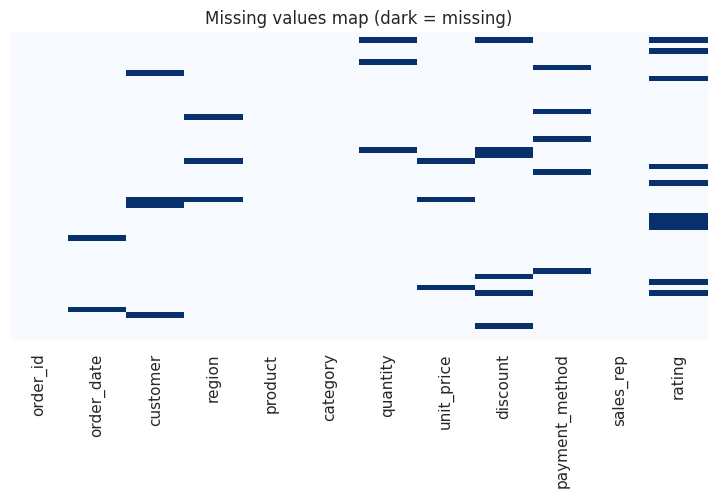

In [49]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Blues")
plt.title("Missing values map (dark = missing)")
plt.show()

### 7.2 Why is it missing? (this decides the treatment)

| Type | Meaning | Example here |
|---|---|---|
| **MCAR** (completely at random) | Gaps unrelated to anything | A typist skipped a field |
| **MAR** (at random, related to other columns) | Gaps depend on another column | Ratings missing more for one payment method |
| **MNAR** (not at random) | Gaps depend on the missing value itself | Unhappy customers skip the rating |

A quick check for MAR: does the share of missing ratings change between groups?

In [50]:
(df.assign(rating_missing=df["rating"].isna())
   .groupby("payment_method", dropna=False)["rating_missing"].mean().round(2))

payment_method
Bank Transfer   0.20
Cash            0.19
Credit Card     0.17
Mobile Money    0.25
NaN             0.00
Name: rating_missing, dtype: float64

### 7.3 Strategies, compared on a tiny example
Notice what each strategy does to this series, especially the effect of the extreme value 300 on the mean.

In [51]:
s = pd.Series([10, 12, np.nan, 11, 300, np.nan, 13], name="value")

pd.DataFrame({
    "original":    s,
    "mean fill":   s.fillna(s.mean()),
    "median fill": s.fillna(s.median()),
    "forward fill": s.ffill(),
    "interpolate": s.interpolate(),
    "constant 0":  s.fillna(0),
})

,original,mean fill,median fill,forward fill,interpolate,constant 0
0,10.00,10.00,10.00,10.00,10.00,10.00
1,12.00,12.00,12.00,12.00,12.00,12.00
2,NaN,69.20,12.00,12.00,11.50,0.00
3,11.00,11.00,11.00,11.00,11.00,11.00
4,300.00,300.00,300.00,300.00,300.00,300.00
5,NaN,69.20,12.00,300.00,156.50,0.00
6,13.00,13.00,13.00,13.00,13.00,13.00


🧭 **Decision guide: how to treat missing values**

| Situation | Recommended action |
|---|---|
| Column is mostly empty and not essential | Drop the column |
| The key identifier is missing | Drop the row |
| Very few rows affected and gaps are random | Dropping rows is acceptable (`dropna`) |
| Numeric, roughly symmetric | Fill with the **mean** |
| Numeric, skewed or has extreme values | Fill with the **median** |
| Numeric that depends on a group (price depends on product) | Fill with the **group median** |
| Categorical | Fill with the **mode** or an explicit `"Unknown"` |
| Missing value can be calculated from other columns | **Recompute** it |
| The fact that it is missing carries meaning (skipped rating) | **Keep `NaN`** and add a True/False flag column |
| Ordered data over time | Forward fill or interpolate |

### 7.4 Applying the strategy column by column

In [52]:
# Text columns: an explicit "Unknown" keeps the rows and is honest about the gap
for col in ["customer", "region", "payment_method"]:
    df[col] = df[col].fillna("Unknown")

# Discount: ASSUMPTION (documented): a missing discount means no discount was given
df["discount"] = df["discount"].fillna(0)

# Rating: the gap may be meaningful, so keep NaN and record where it happened
df["rating_missing"] = df["rating"].isna()

**Group-aware filling.** A missing price should be filled with the price *of the same product*, not the overall average. A laptop is not a notebook.

In [53]:
print("Typical price per product:")
display(df.groupby("product")["unit_price"].median().round(2))

df["unit_price"] = df["unit_price"].fillna(df.groupby("product")["unit_price"].transform("median"))
df["quantity"]   = df["quantity"].fillna(df["quantity"].median())

Typical price per product:

product
Backpack          280.62
Desk            1,829.57
Headphones        449.81
Laptop          6,438.75
Notebook Pack      61.62
Office Chair    1,224.84
Power Bank        214.93
Printer Paper      97.28
Smartphone      3,224.64
Name: unit_price, dtype: float64

💡 `transform("median")` returns a value for **every row** (its group's median), so it lines up with the original rows and can be passed straight to `fillna`.

In [54]:
df.isna().sum()[lambda x: x > 0]      # what is still missing? (only the intentional gaps)

order_date     2
rating        10
dtype: int64

The remaining gaps are intentional: `rating` (kept on purpose, with a flag) and `order_date` (invalid dates, excluded from time charts later).

⚠️ **Never fill missing values blindly.** Ask: *Why is it missing? What will this number be used for? Could filling it mislead someone?*

✍️ **Try it:** fill missing `rating` with the median **per category** on a *copy* of the DataFrame and compare the average rating to the version where `NaN` is kept. How different are they?

## Module 8: Treating outliers

**Learning goals:** tell errors from real extremes; detect outliers with several methods; apply the right treatment.

🧠 An **outlier** is a value far from the rest. Ask three questions in order:

1. **Is it an error?** (wrong unit, extra zero, impossible value) → fix, or set to missing and re-fill
2. **Is it real but extreme?** (a genuine bulk order) → keep it; maybe report the median
3. **Will it distort the method?** (means, regression) → consider capping or transforming

### 8.1 Invalid values are errors, not outliers
Business rules tell us what is **impossible**. For example, quantity must be between 1 and 50.

In [55]:
rules = {
    "quantity outside 1 to 50":   ~df["quantity"].between(1, 50),
    "discount outside 0 to 0.5":  ~df["discount"].between(0, 0.5),
    "unit_price not positive":    df["unit_price"] <= 0,
    "rating outside 1 to 5":      df["rating"].notna() & ~df["rating"].between(1, 5),
}
pd.Series({name: int(mask.sum()) for name, mask in rules.items()}, name="violations")

quantity outside 1 to 50     3
discount outside 0 to 0.5    0
unit_price not positive      0
rating outside 1 to 5        0
Name: violations, dtype: int64

In [56]:
df[~df["quantity"].between(1, 50)][["order_id", "product", "quantity"]]     # the offenders

,order_id,product,quantity
16,ORD-3017,Printer Paper,150.00
39,ORD-3041,Office Chair,400.00
42,ORD-3044,Backpack,-3.00


A quantity of 400 or -3 is a data-entry error. Our treatment: turn the invalid values into missing, then fill with the typical value.

In [57]:
df.loc[~df["quantity"].between(1, 50), "quantity"] = np.nan
df["quantity"] = df["quantity"].fillna(df["quantity"].median()).round().astype(int)    # quantities are whole numbers

df["quantity"].describe()

count   56.00
mean     5.34
std      2.96
min      1.00
25%      3.00
50%      5.00
75%      8.00
max     10.00
Name: quantity, dtype: float64

### 8.2 Detecting outliers in prices

**Method 1: the IQR rule (robust, the default).** A value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`.

**Method 2: the z-score.** A value is unusual if it is more than 3 standard deviations from the mean (assumes roughly bell-shaped data).

**Method 3: look at it.** A box plot shows outliers as dots.

**Method 4: compare with the group's typical value** (ratio to the group median). This is the most dependable rule when each group has only a handful of rows.

In [58]:
def iqr_flags(s, k=1.5):
    """Return True for values outside the IQR fences."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

z = (df["unit_price"] - df["unit_price"].mean()) / df["unit_price"].std()

print("Global IQR flags   :", iqr_flags(df["unit_price"]).sum())
print("Global z-score flags:", (z.abs() > 3).sum())

Global IQR flags   : 4
Global z-score flags: 1


⚠️ **A laptop costs about 6,500 and a notebook pack about 60.** Judging all prices together is the wrong question: a normal laptop looks like an outlier next to notebooks, and a 10x-too-high notebook price may look normal next to laptops. We must judge each price **within its own product**.

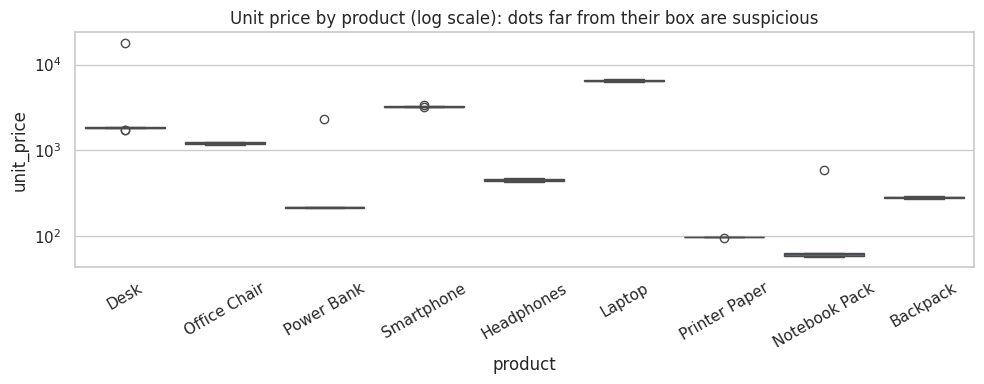

In [59]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="product", y="unit_price")
plt.yscale("log")                    # log scale lets us see cheap and expensive products together
plt.xticks(rotation=30)
plt.title("Unit price by product (log scale): dots far from their box are suspicious")
plt.tight_layout()
plt.show()

In [60]:
# Within each product, two ways to flag a suspicious price
df["iqr_flag"]    = df.groupby("product")["unit_price"].transform(iqr_flags)

df["price_ratio"] = df["unit_price"] / df.groupby("product")["unit_price"].transform("median")
df["ratio_flag"]  = (df["price_ratio"] > 3) | (df["price_ratio"] < 1 / 3)     # 3x higher or 3x lower than typical

print("Flagged by IQR within product       :", df["iqr_flag"].sum())
print("Flagged by ratio-to-median (3x rule):", df["ratio_flag"].sum())

df.loc[df["iqr_flag"] | df["ratio_flag"], ["order_id", "product", "unit_price", "price_ratio", "iqr_flag", "ratio_flag"]]

Flagged by IQR within product       : 8
Flagged by ratio-to-median (3x rule): 3


,order_id,product,unit_price,price_ratio,iqr_flag,ratio_flag
4,ORD-3005,Smartphone,"3,333.40",1.03,True,False
10,ORD-3011,Desk,"1,736.85",0.95,True,False
16,ORD-3017,Printer Paper,93.85,0.96,True,False
20,ORD-3021,Smartphone,"3,160.28",0.98,True,False
21,ORD-3022,Desk,"1,722.55",0.94,True,False
28,ORD-3029,Power Bank,"2,286.60",10.64,True,True
29,ORD-3030,Desk,"17,889.60",9.78,True,True
54,ORD-3056,Notebook Pack,583.90,9.48,True,True


👀 **Compare the two rules.** Look at `price_ratio`:

* Rows flagged by **both** rules have a ratio near **10**: the price is about ten times the product's usual price. That is a classic extra-zero data-entry error.
* Rows flagged **only by the IQR rule** have a ratio close to **1**: perfectly normal prices. With only 5 to 10 rows per product the IQR fences are very tight, so ordinary prices look "extreme".

🧠 **Lesson:** a statistical rule is a *flag for investigation*, not a verdict. Always look at the flagged rows and ask whether they are really errors. Here the ratio rule isolates the true errors, so we use it for treatment.

In [61]:
# Treat confirmed errors: set to missing, then re-fill with the product's typical price
df.loc[df["ratio_flag"], "unit_price"] = np.nan
df["unit_price"] = df["unit_price"].fillna(df.groupby("product")["unit_price"].transform("median"))

check_ratio = df["unit_price"] / df.groupby("product")["unit_price"].transform("median")
print("Suspicious prices left:", ((check_ratio > 3) | (check_ratio < 1 / 3)).sum())

df = df.drop(columns=["iqr_flag", "price_ratio", "ratio_flag"])      # helper columns no longer needed

Suspicious prices left: 0


💡 These prices were replaced by the product's median. If you later learn the true price, correct it from the source system instead.

### 8.3 Other treatments: capping and transforming
Sometimes an extreme value is **real** (a large legitimate order) but still distorts averages. Two common remedies, shown on the estimated order value:

In [62]:
order_value = df["quantity"] * df["unit_price"] * (1 - df["discount"])

low, high = order_value.quantile([0.01, 0.99])
capped = order_value.clip(low, high)               # winsorising: pull extremes in to the 1st/99th percentile
logged = np.log1p(order_value)                      # log transform: compresses a long right tail

pd.DataFrame({
    "original": order_value.describe(),
    "capped":   capped.describe(),
    "log":      logged.describe(),
}).round(2)

,original,capped,log
count,56.00,56.00,56.00
mean,"6,457.82","6,247.32",7.75
std,"9,489.09","8,503.23",1.66
min,54.30,54.36,4.01
25%,695.71,695.71,6.55
50%,"2,459.95","2,459.95",7.78
75%,"8,623.20","8,623.20",9.06
max,"53,626.59","41,838.53",10.89


In [63]:
print("Skewness  original:", round(order_value.skew(), 2),
      "| capped:", round(capped.skew(), 2),
      "| log:", round(logged.skew(), 2))

Skewness  original: 3.02 | capped: 2.41 | log: -0.36


🧭 **Outlier treatment decision guide**

| Treatment | How | Use when |
|---|---|---|
| **Keep** | Do nothing; report the median | The value is real and important |
| **Remove the row** | `df[~mask]` | Confirmed error and the whole row is unreliable |
| **Set to missing, then fill** | `.loc[mask, col] = np.nan` | Confirmed error in one field only |
| **Cap (winsorise)** | `.clip(low, high)` | Real but extreme, and you need stable statistics |
| **Transform** | `np.log1p(x)` | Strong right skew (money, counts) |
| **Analyse separately** | Split into segments | Outliers form their own group (wholesale vs retail) |

⚠️ Never delete outliers just because they are inconvenient. Document every decision and its reason.

✍️ **Try it:** apply `iqr_flags` to `quantity` within each `category`, and also compute each quantity's ratio to its category median. Does any real order look unusual? Would you keep or treat it?

In [64]:
df_clean_snapshot = df.copy()      # save the cleaned (not yet engineered) table: we compare against it in Module 12
df.head()

,order_id,order_date,customer,region,product,category,quantity,unit_price,discount,payment_method,sales_rep,rating,rating_missing
0,ORD-3001,2025-03-25,Nana Yeboah,Ashanti,Desk,Furniture,4,"1,858.06",0.00,Credit Card,Efua Owusu,5.00,False
1,ORD-3002,2025-02-07,Fiifi Ampofo,Volta,Office Chair,Furniture,5,"1,242.13",0.00,Bank Transfer,Ama Serwaa,NaN,True
2,ORD-3003,2025-04-10,Akosua Frimpong,Greater Accra,Power Bank,Accessories,6,211.58,0.10,Bank Transfer,Ama Serwaa,2.00,False
3,ORD-3004,2025-01-19,Kojo Annan,Ashanti,Office Chair,Furniture,9,"1,248.14",0.00,Cash,Ama Serwaa,NaN,True
4,ORD-3005,2025-01-25,Selina Tetteh,Northern,Smartphone,Electronics,2,"3,333.40",0.00,Credit Card,Efua Owusu,5.00,False


## Module 9: Feature engineering

**Learning goals:** create new columns that make patterns visible and prepare data for analysis and machine learning.

🧠 **Feature engineering** means creating new columns from existing ones: calculations, categories, dates, text pieces, group statistics. Good features often matter more than fancy algorithms.

### 9.1 Arithmetic features

In [65]:
df["gross_sales"]     = df["quantity"] * df["unit_price"]
df["discount_amount"] = (df["gross_sales"] * df["discount"]).round(2)
df["total_sales"]     = (df["gross_sales"] - df["discount_amount"]).round(2)

df[["quantity", "unit_price", "discount", "gross_sales", "discount_amount", "total_sales"]].head()

,quantity,unit_price,discount,gross_sales,discount_amount,total_sales
0,4,"1,858.06",0.00,"7,432.24",0.00,"7,432.24"
1,5,"1,242.13",0.00,"6,210.65",0.00,"6,210.65"
2,6,211.58,0.10,"1,269.48",126.95,"1,142.53"
3,9,"1,248.14",0.00,"11,233.26",0.00,"11,233.26"
4,2,"3,333.40",0.00,"6,666.80",0.00,"6,666.80"


### 9.2 True/False flags and conditions
`np.where(condition, value_if_true, value_if_false)` applies a rule to every row at once.

In [66]:
df["has_discount"] = df["discount"] > 0                                  # a True/False column directly
df["is_bulk"]      = np.where(df["quantity"] >= 5, "Bulk", "Single")    # a label
df[["quantity", "is_bulk", "discount", "has_discount"]].head()

,quantity,is_bulk,discount,has_discount
0,4,Single,0.00,False
1,5,Bulk,0.00,False
2,6,Bulk,0.10,True
3,9,Bulk,0.00,False
4,2,Single,0.00,False


For **more than two outcomes** use `np.select(conditions, choices, default)`. Conditions are checked in order; the first match wins.

In [67]:
conditions = [df["total_sales"] >= 10000, df["total_sales"] >= 2000]
choices    = ["Large", "Medium"]
df["order_size"] = np.select(conditions, choices, default="Small")

df["order_size"].value_counts()

order_size
Small     28
Medium    16
Large     12
Name: count, dtype: int64

### 9.3 Binning numbers into groups
* `pd.cut` makes bins with **bounds you choose**
* `pd.qcut` makes bins with **equal numbers of rows** (quantiles)

In [68]:
df["price_band"] = pd.cut(df["unit_price"], bins=[0, 300, 2000, np.inf], labels=["Budget", "Mid-range", "Premium"])
df["sales_quartile"] = pd.qcut(df["total_sales"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

print(df["price_band"].value_counts().sort_index())
print()
print(df["sales_quartile"].value_counts().sort_index())

price_band
Budget       20
Mid-range    27
Premium       9
Name: count, dtype: int64

sales_quartile
Q1 (lowest)     14
Q2              14
Q3              14
Q4 (highest)    14
Name: count, dtype: int64


### 9.4 Date features
The `.dt` accessor pulls pieces out of a date column. Rows with a missing date simply get missing results.

In [69]:
df["year"]       = df["order_date"].dt.year
df["month"]      = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()
df["quarter"]    = df["order_date"].dt.quarter
df["weekday"]    = df["order_date"].dt.day_name()
df["is_weekend"] = df["order_date"].dt.dayofweek >= 5

df[["order_date", "month", "month_name", "quarter", "weekday", "is_weekend"]].head()

,order_date,month,month_name,quarter,weekday,is_weekend
0,2025-03-25,3.00,March,1.00,Tuesday,False
1,2025-02-07,2.00,February,1.00,Friday,False
2,2025-04-10,4.00,April,2.00,Thursday,False
3,2025-01-19,1.00,January,1.00,Sunday,True
4,2025-01-25,1.00,January,1.00,Saturday,True


In [70]:
# Time elapsed: days since the first order in the data
df["days_since_first_order"] = (df["order_date"] - df["order_date"].min()).dt.days
df[["order_date", "days_since_first_order"]].head(3)

,order_date,days_since_first_order
0,2025-03-25,81.00
1,2025-02-07,35.00
2,2025-04-10,97.00


### 9.5 Text features

In [71]:
df["customer_first_name"] = df["customer"].str.split().str[0]
df["product_label"]       = df["category"] + " | " + df["product"]
df["name_length"]         = df["customer"].str.len()
df[["customer", "customer_first_name", "product_label", "name_length"]].head()

,customer,customer_first_name,product_label,name_length
0,Nana Yeboah,Nana,Furniture | Desk,11
1,Fiifi Ampofo,Fiifi,Furniture | Office Chair,12
2,Akosua Frimpong,Akosua,Accessories | Power Bank,15
3,Kojo Annan,Kojo,Furniture | Office Chair,10
4,Selina Tetteh,Selina,Electronics | Smartphone,13


### 9.6 Group-based features (very powerful)
These compare each row to **its group**.

In [72]:
# Each order's value compared with the average for its category
df["category_avg_sales"]  = df.groupby("category")["total_sales"].transform("mean").round(2)
df["vs_category_avg"]     = (df["total_sales"] / df["category_avg_sales"]).round(2)

# Share of the region's revenue
df["share_of_region_%"]   = (df["total_sales"] / df.groupby("region")["total_sales"].transform("sum") * 100).round(1)

# Rank within category (1 = biggest order)
df["rank_in_category"]    = df.groupby("category")["total_sales"].rank(ascending=False, method="dense").astype(int)

# How many orders has each customer placed?
df["customer_orders"]     = df.groupby("customer")["order_id"].transform("count")
df["is_repeat_customer"]  = (df["customer_orders"] > 1) & (df["customer"] != "Unknown")

df[["order_id", "category", "total_sales", "vs_category_avg", "share_of_region_%", "rank_in_category", "is_repeat_customer"]].head()

,order_id,category,total_sales,vs_category_avg,share_of_region_%,rank_in_category,is_repeat_customer
0,ORD-3001,Furniture,"7,432.24",0.92,19.10,12,True
1,ORD-3002,Furniture,"6,210.65",0.77,31.60,14,True
2,ORD-3003,Accessories,"1,142.53",1.03,1.00,4,True
3,ORD-3004,Furniture,"11,233.26",1.39,28.80,3,True
4,ORD-3005,Electronics,"6,666.80",0.59,6.10,8,True


### 9.7 Time-series features: growth and rolling averages
Aggregate to months first, then use `shift` (previous value) and `rolling` (moving average).

In [73]:
dated = df.dropna(subset=["order_date"])
monthly = dated.groupby(dated["order_date"].dt.to_period("M"))["total_sales"].sum().to_frame("sales")

monthly["previous_month"] = monthly["sales"].shift(1)
monthly["growth_%"]       = ((monthly["sales"] / monthly["previous_month"] - 1) * 100).round(1)
monthly["rolling_3m_avg"] = monthly["sales"].rolling(3).mean().round(0)
monthly

,sales,previous_month,growth_%,rolling_3m_avg
order_date,,,,
2025-01,"71,406.18",NaN,NaN,NaN
2025-02,"26,916.75","71,406.18",-62.30,NaN
2025-03,"41,558.00","26,916.75",54.40,"46,627.00"
2025-04,"56,208.61","41,558.00",35.30,"41,561.00"
2025-05,"42,043.46","56,208.61",-25.20,"46,603.00"
2025-06,"68,293.49","42,043.46",62.40,"55,515.00"


### 9.8 Preparing features for machine learning: encoding and scaling
Most models need **numbers only**. We do this on a separate copy so our clean table stays readable.

* **One-hot encoding** turns each category into 0/1 columns (`pd.get_dummies`)
* **Scaling** puts numbers on comparable ranges (standardisation or min-max)
* **Log transform** tames skewed amounts

⚠️ In real machine-learning projects, compute scaling statistics from the **training data only** and apply them to the test data. Otherwise information leaks from the test set.

In [74]:
df_ml = df[["quantity", "unit_price", "discount", "total_sales", "payment_method", "category"]].copy()

df_ml = pd.get_dummies(df_ml, columns=["payment_method", "category"], drop_first=True, dtype=int)

df_ml["total_sales_log"]  = np.log1p(df_ml["total_sales"])
df_ml["unit_price_z"]     = (df_ml["unit_price"] - df_ml["unit_price"].mean()) / df_ml["unit_price"].std()
df_ml["quantity_minmax"]  = (df_ml["quantity"] - df_ml["quantity"].min()) / (df_ml["quantity"].max() - df_ml["quantity"].min())

df_ml.head()

,quantity,unit_price,discount,total_sales,payment_method_Cash,payment_method_Credit Card,payment_method_Mobile Money,payment_method_Unknown,category_Electronics,category_Furniture,category_Stationery,total_sales_log,unit_price_z,quantity_minmax
0,4,"1,858.06",0.00,"7,432.24",0,1,0,0,0,1,0,8.91,0.34,0.33
1,5,"1,242.13",0.00,"6,210.65",0,0,0,0,0,1,0,8.73,-0.04,0.44
2,6,211.58,0.10,"1,142.53",0,0,0,0,0,0,0,7.04,-0.69,0.56
3,9,"1,248.14",0.00,"11,233.26",1,0,0,0,0,1,0,9.33,-0.04,0.89
4,2,"3,333.40",0.00,"6,666.80",0,1,0,0,1,0,0,8.81,1.27,0.11


🧭 **Which feature technique when?**

| Goal | Technique |
|---|---|
| Combine numbers | Arithmetic columns (`price * qty`) |
| Turn a rule into a label | `np.where`, `np.select` |
| Group a number into ranges | `pd.cut` (fixed bounds), `pd.qcut` (equal counts) |
| Use dates | `.dt.month`, `.dt.dayofweek`, differences between dates |
| Compare a row with its group | `groupby(...).transform(...)` |
| Look at change over time | `shift`, `rolling`, `pct_change` |
| Prepare for models | `get_dummies`, scaling, `np.log1p` |

✍️ **Try it:** create a `price_to_category_avg` feature (`unit_price` divided by the category's average price), and a `is_q4_order` flag. Which one would help explain differences between orders?

## Module 10: Summarising and reshaping

**Learning goals:** answer business questions with `groupby`, pivot tables, `crosstab`, `melt` and `merge`.

### 10.1 groupby: split, apply, combine

In [75]:
df.groupby("region")["total_sales"].sum().sort_values(ascending=False)

region
Greater Accra   110,772.62
Northern        109,724.09
Western          62,989.54
Ashanti          38,997.15
Volta            19,678.90
Unknown          19,475.78
Name: total_sales, dtype: float64

In [76]:
# Several measures at once with named aggregation
category_summary = df.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("total_sales", "sum"),
    avg_order=("total_sales", "mean"),
    avg_quantity=("quantity", "mean"),
    avg_rating=("rating", "mean"),
).round(2).sort_values("revenue", ascending=False)
category_summary

,orders,revenue,avg_order,avg_quantity,avg_rating
category,,,,,
Electronics,18,"203,346.52","11,297.03",4.94,3.27
Furniture,18,"145,322.45","8,073.47",5.94,3.14
Accessories,7,"7,760.07","1,108.58",5.00,2.67
Stationery,13,"5,209.04",400.70,5.23,2.73


In [77]:
# Group by two columns
df.groupby(["region", "category"])["total_sales"].sum().round(0).head(8)

region         category   
Ashanti        Accessories    1,075.00
               Electronics   13,370.00
               Furniture     24,358.00
               Stationery       195.00
Greater Accra  Accessories    1,143.00
               Electronics   79,626.00
               Furniture     29,662.00
               Stationery       343.00
Name: total_sales, dtype: float64

### 10.2 Pivot tables and cross-tabulations

In [78]:
pivot = pd.pivot_table(df, values="total_sales", index="region", columns="category",
                       aggfunc="sum", fill_value=0, margins=True, margins_name="Total").round(0)
pivot

category,Accessories,Electronics,Furniture,Stationery,Total
region,,,,,
Ashanti,"1,075.00","13,370.00","24,358.00",195.00,"38,997.00"
Greater Accra,"1,143.00","79,626.00","29,662.00",343.00,"110,773.00"
Northern,"2,199.00","71,080.00","35,282.00","1,163.00","109,724.00"
Unknown,0.00,"8,707.00","10,122.00",647.00,"19,476.00"
Volta,0.00,"3,543.00","14,823.00","1,313.00","19,679.00"
Western,"3,344.00","27,022.00","31,074.00","1,549.00","62,990.00"
Total,"7,760.00","203,347.00","145,322.00","5,209.00","361,638.00"


In [79]:
pd.crosstab(df["region"], df["payment_method"], margins=True)            # counts of combinations

payment_method,Bank Transfer,Cash,Credit Card,Mobile Money,Unknown,All
region,,,,,,
Ashanti,1,2,3,0,1,7
Greater Accra,5,6,0,3,2,16
Northern,4,2,3,3,1,13
Unknown,0,0,3,0,0,3
Volta,1,3,2,0,1,7
Western,4,3,1,2,0,10
All,15,16,12,8,5,56


In [80]:
pd.crosstab(df["region"], df["payment_method"], normalize="index").round(2)   # row percentages

payment_method,Bank Transfer,Cash,Credit Card,Mobile Money,Unknown
region,,,,,
Ashanti,0.14,0.29,0.43,0.00,0.14
Greater Accra,0.31,0.38,0.00,0.19,0.12
Northern,0.31,0.15,0.23,0.23,0.08
Unknown,0.00,0.00,1.00,0.00,0.00
Volta,0.14,0.43,0.29,0.00,0.14
Western,0.40,0.30,0.10,0.20,0.00


### 10.3 Wide to long: `melt`
Charting libraries and BI tools often prefer **long** tables (one measurement per row).

In [81]:
wide = pivot.drop(index="Total", columns="Total").reset_index()
long = wide.melt(id_vars="region", var_name="category", value_name="sales")
long.head(8)

,region,category,sales
0,Ashanti,Accessories,"1,075.00"
1,Greater Accra,Accessories,"1,143.00"
2,Northern,Accessories,"2,199.00"
3,Unknown,Accessories,0.00
4,Volta,Accessories,0.00
5,Western,Accessories,"3,344.00"
6,Ashanti,Electronics,"13,370.00"
7,Greater Accra,Electronics,"79,626.00"


### 10.4 Combining tables: `merge`
Add information from another table by matching on a shared column. `how="left"` keeps **all rows of the left table**.

In [82]:
rep_df = pd.DataFrame(rep_info)
rep_df

,sales_rep,team,years_experience
0,Kwame Mensah,North,6
1,Ama Serwaa,South,3
2,Kofi Boateng,North,8
3,Efua Owusu,South,2


In [83]:
rows_before = len(df)
df_merged = df.merge(rep_df, on="sales_rep", how="left")

print("Rows before:", rows_before, "| after:", len(df_merged))     # must be equal: a bigger number means duplicate keys!
df_merged.groupby("team")["total_sales"].sum().round(0)

Rows before: 56 | after: 56


team
North   166,704.00
South   194,934.00
Name: total_sales, dtype: float64

⚠️ **Always compare row counts before and after a merge.** If the count grows, the table you merged in has duplicate keys.

✍️ **Try it:** find the average `total_sales` per `years_experience` of the sales rep. Does more experience mean larger orders in this data?

## Module 11: Making charts

**Learning goals:** pick the right chart for the question; build clear, honest, labelled charts.

🧭 **Chart chooser**

| Your question | Chart | Avoid |
|---|---|---|
| How is a number distributed? | Histogram, box plot | Bar of raw values |
| Compare a number across categories | Sorted bar chart | Pie with many slices |
| Compare distributions across groups | Box or violin plot | Overlapping histograms |
| Trend over time | Line chart | Bars for dense series |
| Relationship between two numbers | Scatter plot | Line chart |
| Two categories and a number | Heatmap of a pivot table | 3D charts |
| Relationships among many numbers | Correlation heatmap | |

**Rules for honest charts:** title that states the point · labelled axes with units · bar charts start at zero · sort bars · few colours.

### 11.1 Distribution

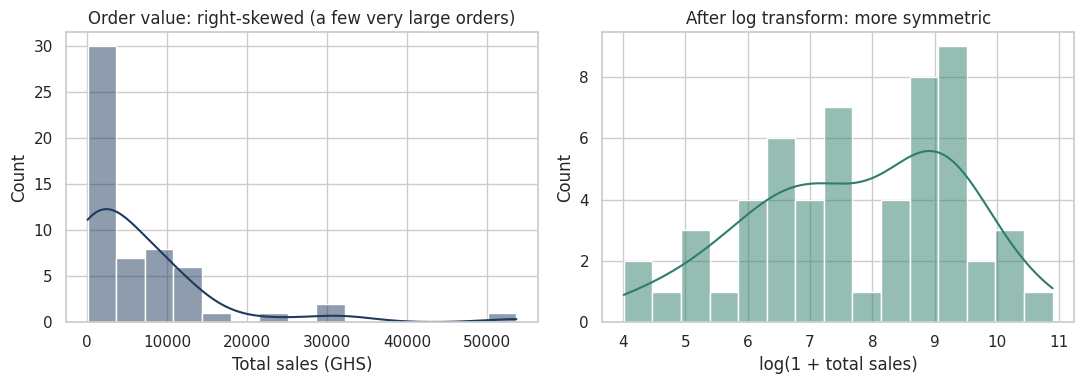

In [84]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["total_sales"], bins=15, kde=True, ax=ax[0], color="#1F3A5F")
ax[0].set_title("Order value: right-skewed (a few very large orders)")
ax[0].set_xlabel("Total sales (GHS)")

sns.histplot(np.log1p(df["total_sales"]), bins=15, kde=True, ax=ax[1], color="#2E7D6B")
ax[1].set_title("After log transform: more symmetric")
ax[1].set_xlabel("log(1 + total sales)")

plt.tight_layout()
plt.show()

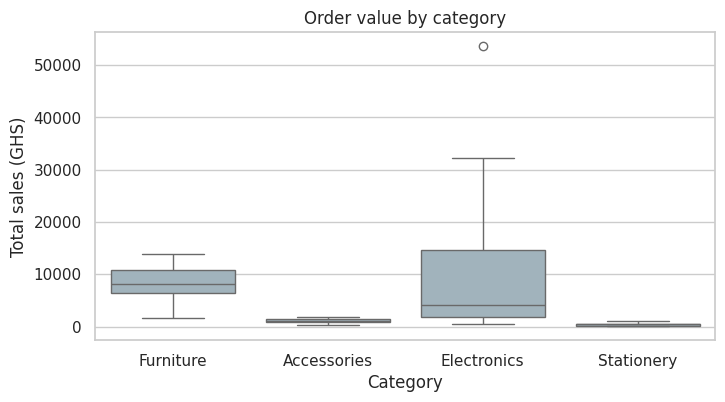

In [85]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="category", y="total_sales", color="#9DB4C0")
plt.title("Order value by category")
plt.xlabel("Category")
plt.ylabel("Total sales (GHS)")
plt.show()

### 11.2 Comparison

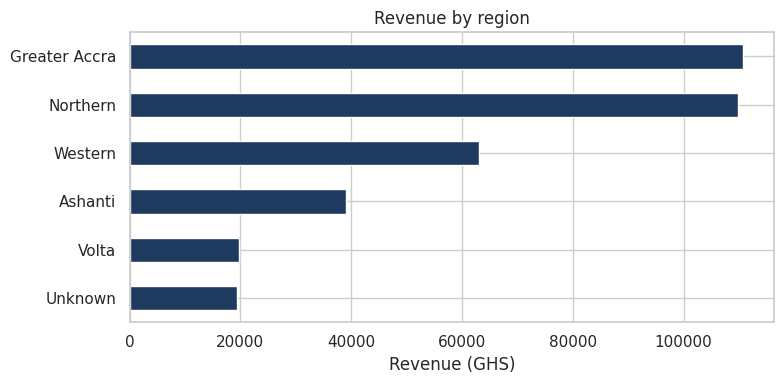

In [86]:
revenue_by_region = df.groupby("region")["total_sales"].sum().sort_values()

revenue_by_region.plot(kind="barh", color="#1F3A5F", figsize=(8, 4))
plt.title("Revenue by region")
plt.xlabel("Revenue (GHS)")
plt.ylabel("")
plt.tight_layout()
plt.show()

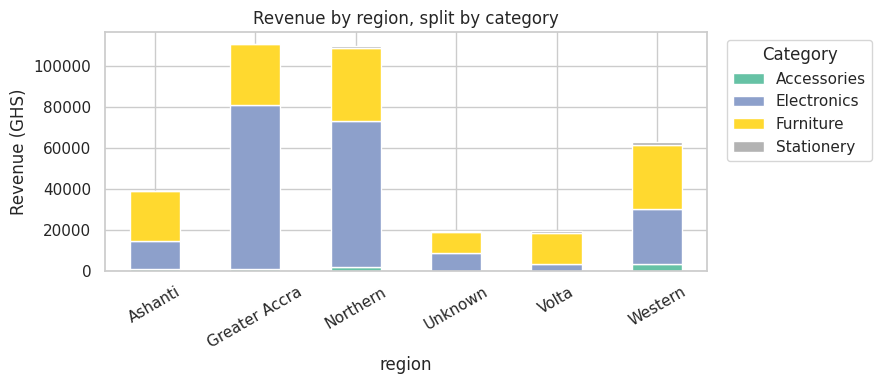

In [87]:
pd.pivot_table(df, values="total_sales", index="region", columns="category", aggfunc="sum", fill_value=0).plot(
    kind="bar", stacked=True, figsize=(9, 4), colormap="Set2")
plt.title("Revenue by region, split by category")
plt.ylabel("Revenue (GHS)")
plt.xticks(rotation=30)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 11.3 Trend over time
Rows with an invalid date are excluded because they cannot be placed on a time axis.

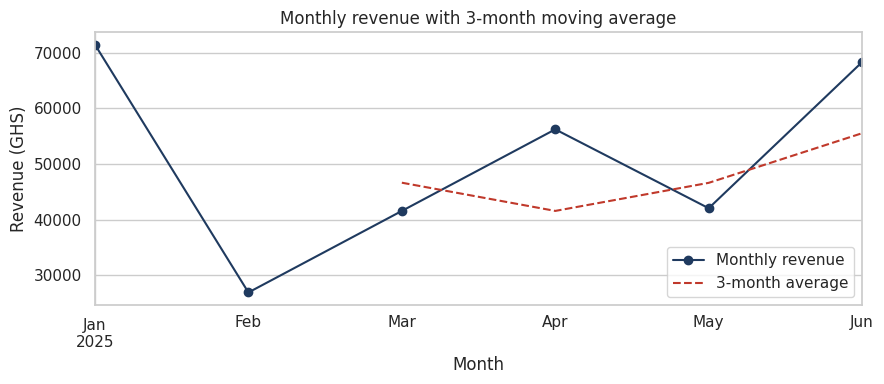

In [88]:
trend = monthly["sales"]
ax = trend.plot(marker="o", figsize=(9, 4), color="#1F3A5F", label="Monthly revenue")
monthly["rolling_3m_avg"].plot(ax=ax, linestyle="--", color="#C0392B", label="3-month average")
ax.set_title("Monthly revenue with 3-month moving average")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (GHS)")
ax.legend()
plt.tight_layout()
plt.show()

### 11.4 Relationships

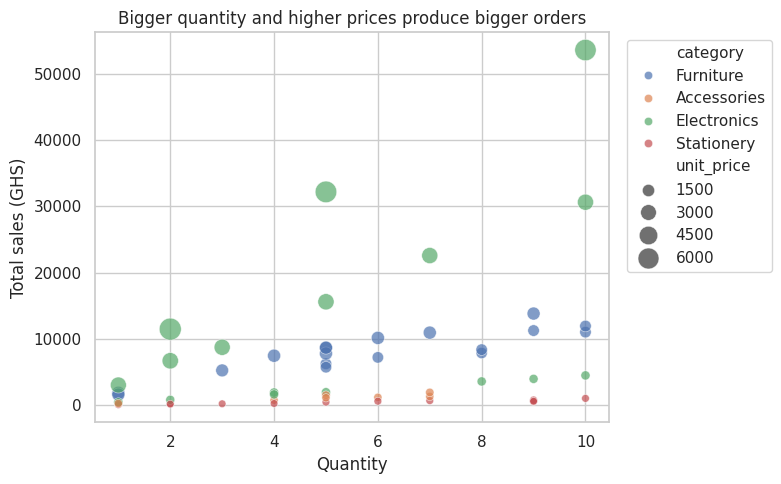

In [89]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="quantity", y="total_sales", hue="category", size="unit_price", sizes=(30, 250), alpha=0.7)
plt.title("Bigger quantity and higher prices produce bigger orders")
plt.xlabel("Quantity")
plt.ylabel("Total sales (GHS)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

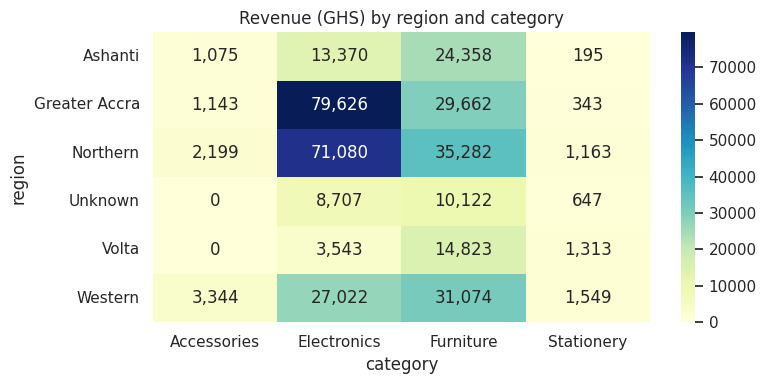

In [90]:
plt.figure(figsize=(8, 4))
sns.heatmap(pivot.drop(index="Total", columns="Total"), annot=True, fmt=",.0f", cmap="YlGnBu")
plt.title("Revenue (GHS) by region and category")
plt.tight_layout()
plt.show()

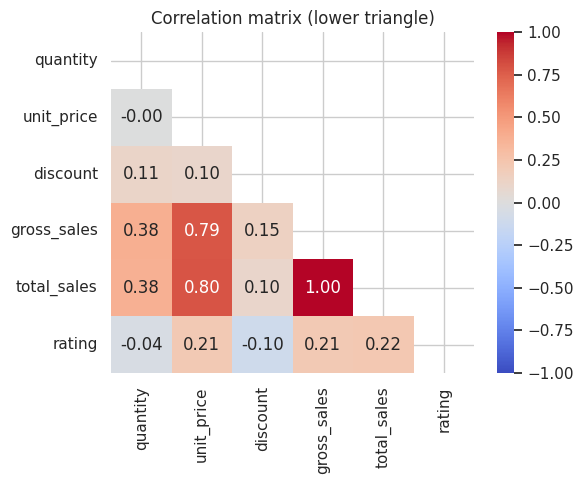

In [91]:
corr = df[["quantity", "unit_price", "discount", "gross_sales", "total_sales", "rating"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation matrix (lower triangle)")
plt.tight_layout()
plt.show()

💡 `total_sales` correlates strongly with `gross_sales` **because it is calculated from it**. Correlation by construction tells you nothing new. Also remember: correlation is not causation.

### 11.5 A one-page summary figure you can save

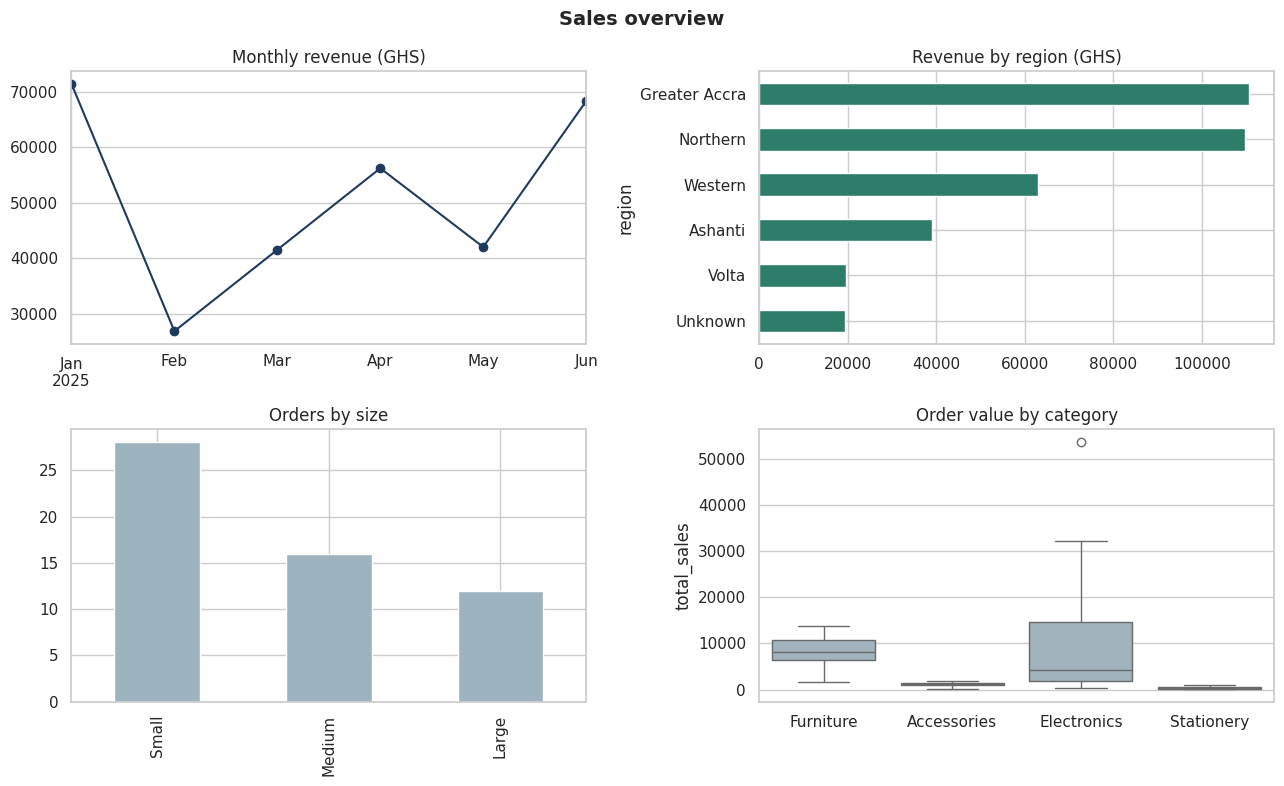

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

trend.plot(ax=axes[0, 0], marker="o", color="#1F3A5F", title="Monthly revenue (GHS)")
revenue_by_region.plot(kind="barh", ax=axes[0, 1], color="#2E7D6B", title="Revenue by region (GHS)")
df["order_size"].value_counts().reindex(["Small", "Medium", "Large"]).plot(
    kind="bar", ax=axes[1, 0], color="#9DB4C0", title="Orders by size")
sns.boxplot(data=df, x="category", y="total_sales", ax=axes[1, 1], color="#9DB4C0")
axes[1, 1].set_title("Order value by category")

for a in axes.ravel():
    a.set_xlabel("")
plt.suptitle("Sales overview", fontsize=14, fontweight="bold")
plt.tight_layout()

Path("output").mkdir(exist_ok=True)
fig.savefig("output/sales_overview.png", dpi=200, bbox_inches="tight")    # save for reports and slides
plt.show()

✍️ **Try it:** (1) draw a bar chart of the **average rating** by payment method, remembering that bar charts start at zero; (2) draw a histogram of `quantity`; (3) write one sentence that states what each chart tells a manager.

## Module 12: Building a reusable cleaning pipeline

**Learning goals:** turn interactive steps into one function that anyone can run on fresh data, and test that it gives the same answer.

🧠 A **pipeline** makes cleaning repeatable. Next month's file goes through exactly the same steps, with no copy-pasting cells.

In [93]:
def iqr_flags(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


def clean_sales(sales_dict: dict) -> pd.DataFrame:
    """Raw dictionary in, clean DataFrame out. Steps follow Modules 5 to 8."""
    d = pd.DataFrame(sales_dict)

    # 1. Standardise text and types
    for col in ["customer", "region", "product", "category", "payment_method", "sales_rep"]:
        d[col] = d[col].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
    d["region"] = d["region"].replace({"Accra": "Greater Accra"})
    d["order_date"] = pd.to_datetime(d["order_date"], format="%Y-%m-%d", errors="coerce")

    # 2. Duplicates: exact first, then conflicting keys (keep the latest entry)
    d = d.drop_duplicates().drop_duplicates("order_id", keep="last").reset_index(drop=True)

    # 3. Missing values
    for col in ["customer", "region", "payment_method"]:
        d[col] = d[col].fillna("Unknown")
    d["discount"] = d["discount"].fillna(0)
    d["rating_missing"] = d["rating"].isna()
    d["unit_price"] = d["unit_price"].fillna(d.groupby("product")["unit_price"].transform("median"))
    d["quantity"] = d["quantity"].fillna(d["quantity"].median())

    # 4. Invalid values and outliers
    d.loc[~d["quantity"].between(1, 50), "quantity"] = np.nan
    d["quantity"] = d["quantity"].fillna(d["quantity"].median()).round().astype(int)
    price_ratio = d["unit_price"] / d.groupby("product")["unit_price"].transform("median")
    d.loc[(price_ratio > 3) | (price_ratio < 1 / 3), "unit_price"] = np.nan
    d["unit_price"] = d["unit_price"].fillna(d.groupby("product")["unit_price"].transform("median"))
    return d


def add_features(d: pd.DataFrame) -> pd.DataFrame:
    """Feature engineering from Module 9 (the core features)."""
    return d.assign(
        gross_sales=lambda x: x["quantity"] * x["unit_price"],
        discount_amount=lambda x: (x["quantity"] * x["unit_price"] * x["discount"]).round(2),
        total_sales=lambda x: (x["gross_sales"] - x["discount_amount"]).round(2),
        has_discount=lambda x: x["discount"] > 0,
        order_size=lambda x: np.select([x["total_sales"] >= 10000, x["total_sales"] >= 2000], ["Large", "Medium"], "Small"),
        price_band=lambda x: pd.cut(x["unit_price"], [0, 300, 2000, np.inf], labels=["Budget", "Mid-range", "Premium"]),
        year=lambda x: x["order_date"].dt.year,
        month=lambda x: x["order_date"].dt.month,
        month_name=lambda x: x["order_date"].dt.month_name(),
        quarter=lambda x: x["order_date"].dt.quarter,
        weekday=lambda x: x["order_date"].dt.day_name(),
        is_weekend=lambda x: x["order_date"].dt.dayofweek >= 5,
    )

### Test: does the pipeline reproduce our step-by-step result?
We compare the function's output with the table we cleaned by hand in Modules 5 to 8 (`df_clean_snapshot`). If they match, the function is correct.

In [94]:
rebuilt = clean_sales(sales_dict)

pd.testing.assert_frame_equal(rebuilt, df_clean_snapshot, check_dtype=False)
print("✅ The pipeline reproduces the manual cleaning exactly.")
print("Rows:", len(rebuilt), "| columns:", rebuilt.shape[1])

✅ The pipeline reproduces the manual cleaning exactly.
Rows: 56 | columns: 13


### Quality checks: a safety net before saving
Automated checks catch problems early. In production pipelines a failed check **stops** the process.

In [95]:
def run_quality_checks(d: pd.DataFrame) -> pd.Series:
    checks = {
        "order_id is unique":              d["order_id"].is_unique,
        "order_id has no gaps":            d["order_id"].notna().all(),
        "quantity between 1 and 50":       d["quantity"].between(1, 50).all(),
        "unit_price is positive":          (d["unit_price"] > 0).all(),
        "discount between 0 and 0.5":      d["discount"].between(0, 0.5).all(),
        "total matches the formula":       np.allclose(d["total_sales"],
                                               d["quantity"] * d["unit_price"] * (1 - d["discount"]), atol=0.01),
        "no text column has stray spaces": all((d[c] == d[c].str.strip()).all()
                                               for c in ["customer", "region", "product", "payment_method"]),
        "at least 90% of dates valid":     d["order_date"].notna().mean() >= 0.90,
    }
    return pd.Series(checks, name="passed")

final = clean_sales(sales_dict).pipe(add_features)
results = run_quality_checks(final)
print(results.to_string())
assert results.all(), "A quality check failed: do NOT save this data."

order_id is unique                 True
order_id has no gaps               True
quantity between 1 and 50          True
unit_price is positive             True
discount between 0 and 0.5         True
total matches the formula          True
no text column has stray spaces    True
at least 90% of dates valid        True


💡 **`.pipe()`** passes a DataFrame through a function, so steps read like a recipe: `clean_sales(raw_data).pipe(add_features)`.

✍️ **Try it:** add one more check, for example *"rating is between 1 and 5 where it exists"*. Then deliberately break the data (set a `quantity` to 999 after cleaning) and watch the check fail.

## Module 13: Saving the cleaned data as a CSV file

**Learning goals:** export with the right options and verify the file by reading it back.

🧠 A CSV is plain text with one row per line and commas between values. It opens in Excel, Power BI, Tableau and every programming language.

| `to_csv` option | Why it matters |
|---|---|
| `index=False` | Stops pandas writing the 0, 1, 2... row numbers as an extra column |
| `encoding="utf-8-sig"` | Lets Excel display special characters (é, ñ, ₵) correctly |
| `date_format="%Y-%m-%d"` | Writes dates in an unambiguous, standard format |
| `columns=[...]` | Chooses which columns to write, and in what order |
| `na_rep=""` | What to write for missing values (blank by default) |

In [96]:
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

column_order = [
    "order_id", "order_date", "year", "month", "month_name", "quarter", "weekday", "is_weekend",
    "customer", "region", "sales_rep", "product", "category", "price_band",
    "quantity", "unit_price", "discount", "has_discount", "gross_sales", "discount_amount", "total_sales", "order_size",
    "payment_method", "rating", "rating_missing",
]

csv_path = output_dir / "sales_clean.csv"
final[column_order].to_csv(csv_path, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

print("Saved:", csv_path, "|", round(csv_path.stat().st_size / 1024, 1), "KB")

Saved: output/sales_clean.csv | 10.5 KB


### Verify: read the file back and compare
Never assume a save worked. Reading the file back is the final quality check.

In [97]:
check = pd.read_csv(csv_path, parse_dates=["order_date"])

print("Shape saved vs reloaded:", final[column_order].shape, check.shape)
print("order_date is a real date:", pd.api.types.is_datetime64_any_dtype(check["order_date"]))
print("Missing values (only rating and bad dates should remain):")
print(check.isna().sum()[lambda x: x > 0].to_string())
check.head()

Shape saved vs reloaded: (56, 25) (56, 25)
order_date is a real date: True
Missing values (only rating and bad dates should remain):
order_date     2
year           2
month          2
month_name     2
quarter        2
weekday        2
rating        10


,order_id,order_date,year,month,month_name,quarter,weekday,is_weekend,customer,region,sales_rep,product,category,price_band,quantity,unit_price,discount,has_discount,gross_sales,discount_amount,total_sales,order_size,payment_method,rating,rating_missing
0,ORD-3001,2025-03-25,"2,025.00",3.00,March,1.00,Tuesday,False,Nana Yeboah,Ashanti,Efua Owusu,Desk,Furniture,Mid-range,4,"1,858.06",0.00,False,"7,432.24",0.00,"7,432.24",Medium,Credit Card,5.00,False
1,ORD-3002,2025-02-07,"2,025.00",2.00,February,1.00,Friday,False,Fiifi Ampofo,Volta,Ama Serwaa,Office Chair,Furniture,Mid-range,5,"1,242.13",0.00,False,"6,210.65",0.00,"6,210.65",Medium,Bank Transfer,NaN,True
2,ORD-3003,2025-04-10,"2,025.00",4.00,April,2.00,Thursday,False,Akosua Frimpong,Greater Accra,Ama Serwaa,Power Bank,Accessories,Budget,6,211.58,0.10,True,"1,269.48",126.95,"1,142.53",Small,Bank Transfer,2.00,False
3,ORD-3004,2025-01-19,"2,025.00",1.00,January,1.00,Sunday,True,Kojo Annan,Ashanti,Ama Serwaa,Office Chair,Furniture,Mid-range,9,"1,248.14",0.00,False,"11,233.26",0.00,"11,233.26",Large,Cash,NaN,True
4,ORD-3005,2025-01-25,"2,025.00",1.00,January,1.00,Saturday,True,Selina Tetteh,Northern,Efua Owusu,Smartphone,Electronics,Premium,2,"3,333.40",0.00,False,"6,666.80",0.00,"6,666.80",Medium,Credit Card,5.00,False


### Save a data dictionary too
A data dictionary documents every column so others (and future you) understand the file.

In [98]:
descriptions = {
    "order_id": "Unique order reference", "order_date": "Date of the order (blank if the original was invalid)",
    "year": "Year of the order", "month": "Month number 1-12", "month_name": "Month name",
    "quarter": "Calendar quarter 1-4", "weekday": "Day of the week", "is_weekend": "True for Saturday or Sunday",
    "customer": "Customer name ('Unknown' if not recorded)", "region": "Ghana region of the sale",
    "sales_rep": "Salesperson", "product": "Product sold", "category": "Product category",
    "price_band": "Budget (<=300), Mid-range (<=2000) or Premium", "quantity": "Units sold (whole number, 1-50)",
    "unit_price": "Price per unit in GHS", "discount": "Discount fraction (missing treated as 0)",
    "has_discount": "True if a discount was given", "gross_sales": "quantity x unit_price (GHS)",
    "discount_amount": "Value of the discount (GHS)", "total_sales": "gross_sales minus discount_amount (GHS)",
    "order_size": "Large (>=10,000), Medium (>=2,000) or Small", "payment_method": "How the customer paid",
    "rating": "Customer rating 1-5 (blank if not given)", "rating_missing": "True if the customer gave no rating",
}

data_dictionary = pd.DataFrame({
    "column": column_order,
    "dtype": [str(check[c].dtype) for c in column_order],
    "description": [descriptions[c] for c in column_order],
    "missing": [int(check[c].isna().sum()) for c in column_order],
})
data_dictionary.to_csv(output_dir / "sales_data_dictionary.csv", index=False, encoding="utf-8-sig")
data_dictionary.head(8)

,column,dtype,description,missing
0,order_id,str,Unique order reference,0
1,order_date,datetime64[us],Date of the order (blank if the original was i...,2
2,year,float64,Year of the order,2
3,month,float64,Month number 1-12,2
4,month_name,str,Month name,2
5,quarter,float64,Calendar quarter 1-4,2
6,weekday,str,Day of the week,2
7,is_weekend,bool,True for Saturday or Sunday,0


### Other formats (for reference)
```python
final.to_excel("output/sales_clean.xlsx", index=False, sheet_name="sales")   # needs: pip install openpyxl
final.to_parquet("output/sales_clean.parquet", index=False)                  # needs: pip install pyarrow; fast, keeps data types
final.to_json("output/sales_clean.json", orient="records", date_format="iso")
```

🧭 **Choosing a format**

| Format | Choose when |
|---|---|
| CSV | Sharing with anyone, small and medium data, any tool |
| Excel | Business users who want formatting or multiple sheets |
| Parquet | Large data, speed, and keeping data types exactly |
| JSON | Web applications and APIs |
| Database (`to_sql`) | Many users or dashboards need the same live table |

### 💡 Tip: keep your project tidy
```
project/
    data/raw/          # original files, never edited
    data/processed/    # cleaned outputs
    notebooks/         # this notebook
    output/            # charts and reports
```

## Module 14: Capstone, cheat sheet and next steps

### 🎯 Capstone: Regional Sales Review (60 minutes, no hints)
Use only `sales_dict` and the skills from this notebook. In a **new notebook**:

1. Build the DataFrame and inspect it (write 3 problems you notice)
2. Clean it with your **own** `clean_sales` function (do not copy mine); document every assumption in markdown
3. Create at least **5 new features** and justify each
4. Answer these business questions with code **and a chart each**:
   * Which region and which category earn the most?
   * Is revenue growing month over month?
   * Do discounts lead to bigger orders?
5. Save the cleaned data and a data dictionary as CSV, and read them back to verify
6. Write **three sentences** a manager could act on

### 📋 Cheat sheet

| Task | Code |
|---|---|
| Create from dictionary | `pd.DataFrame(d)` · `pd.DataFrame.from_dict(d, orient="index")` |
| Inspect | `df.head()` · `df.info()` · `df.describe()` · `df.shape` · `df.dtypes` |
| Select | `df["a"]` · `df[["a","b"]]` · `df.loc[rows, cols]` · `df.iloc[0:5]` |
| Filter | `df[df["a"] > 5]` · `&` `\|` `~` · `.isin([...])` · `.between(a, b)` · `.query("...")` |
| Sort | `df.sort_values("a", ascending=False)` · `df.nlargest(5, "a")` |
| Types | `pd.to_numeric(errors="coerce")` · `pd.to_datetime(errors="coerce")` · `.astype(...)` |
| Text | `.str.strip()` · `.str.lower()` · `.str.title()` · `.str.replace()` · `.str.contains()` |
| Missing | `df.isna().sum()` · `fillna(...)` · `dropna(subset=[...])` · `ffill()` · `interpolate()` |
| Duplicates | `df.duplicated()` · `drop_duplicates(subset=..., keep=...)` |
| Outliers | IQR fences · z-score · `.clip(lo, hi)` · `np.log1p()` |
| New columns | `df["c"] = ...` · `np.where` · `np.select` · `pd.cut` · `pd.qcut` · `.dt.month` |
| Group | `groupby().agg()` · `transform()` · `pivot_table()` · `crosstab()` |
| Combine | `merge(on=..., how="left")` · `pd.concat([...])` · `melt()` |
| Save | `df.to_csv(path, index=False)` · `pd.read_csv(path, parse_dates=[...])` |

### ⚠️ Common errors and fixes

| Symptom | Likely cause | Fix |
|---|---|---|
| `ValueError: arrays must all be same length` | Lists of different lengths in a dictionary | Check `len()` of every list |
| `KeyError: 'region'` | Wrong or misspelt column name, or trailing space | `df.columns.tolist()` |
| Filter returns nothing | Hidden spaces or capitalisation differences | `.str.strip().str.title()` first |
| `SettingWithCopyWarning` | Modifying a slice | Use `.copy()` or `.loc[mask, col] = value` |
| Totals look too high | Duplicate rows | Check `duplicated()` and key uniqueness |
| Row count grows after a merge | Duplicate keys in the right table | Deduplicate the key first |
| Average ignores some rows | `NaN` skipped silently | Compare `count()` with `len()` |
| `TypeError` adding numbers | Numbers stored as text | `pd.to_numeric` |
| Date sorting looks wrong | Dates stored as text | `pd.to_datetime` |
| Extra "Unnamed: 0" column after reload | Saved with the index | `to_csv(index=False)` |

### ✅ Mastery checklist
Tick these in your own copy (change `[ ]` to `[x]`). You are a confident beginner-to-intermediate pandas user when you can do all of them **without looking anything up**.

- [ ] Build a DataFrame from a dictionary of lists and from a list of dictionaries
- [ ] Inspect any dataset and list its problems
- [ ] Select and filter with several combined conditions
- [ ] Convert text to numbers and dates safely
- [ ] Standardise messy text
- [ ] Find and resolve exact, hidden and conflicting duplicates
- [ ] Choose a missing-value strategy per column and explain why
- [ ] Separate invalid values from outliers and treat each correctly
- [ ] Create features with conditions, bins, dates, text and group statistics
- [ ] Summarise with `groupby`, pivot tables and `merge`
- [ ] Choose the right chart and make it clear and honest
- [ ] Wrap cleaning in a function and test it
- [ ] Save to CSV with the right options and verify by reading it back

### 🚀 Next steps
1. **Practise** with `Pandas_Workout.ipynb` (new dataset, 32 tasks, self-checks)
2. Clean a **real dataset** from your own work or a public source (Kaggle, government open data)
3. Learn **SQL** for pulling data and **statistics** for drawing conclusions (hypothesis tests, confidence intervals)
4. Build a **dashboard** in Power BI or Tableau from `sales_clean.csv`
5. Try **machine learning** with scikit-learn, using the encoding and scaling ideas from Module 9